In [1]:
# Needed imports
import heapq
from collections import defaultdict
import random
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import heapq
from scipy import signal

## Part 2.1 : Source Information
### Question 2 :
Write a function called entropy_rate that, by receiving the input alphabet table, calculates the entropy rate and compares it with the theoretical result.

In [2]:

# ---------------------------------------------
# Part 2.1 - Question 2: Entropy Rate 
# ---------------------------------------------

def entropy_rate(symbol_probs):
    """
    Computes the entropy rate of a discrete information source.

    Parameters:
        symbol_probs (dict): Dictionary of symbols and their probabilities.

    Returns:
        H (float): Entropy rate in bits per symbol.
    """
    probs = np.array(list(symbol_probs.values()))
    
    # Avoid log(0) by filtering zero probabilities
    probs = probs[probs > 0]
    
    H = -np.sum(probs * np.log2(probs))
    return H


# Alphabet and probabilities (Table 1)
symbol_probs = {
    'A': 0.25,
    'B': 0.20,
    'C': 0.15,
    'D': 0.10,
    'E': 0.08,
    'F': 0.07,
    'G': 0.05,
    'H': 0.04,
    'I': 0.04,
    'J': 0.02
}

# Numerical entropy calculation
H_numerical = entropy_rate(symbol_probs)

# Theoretical entropy (from manual calculation but it is not the exact value I wrote it to 8 decimal places )
H_theoretical = 2.96766888

# Comparison
print(f"Numerical Entropy Rate  : {H_numerical:.10f} bits/symbol")
print(f"Theoretical Entropy (To 6 decimal places)    : {H_theoretical:.6f} bits/symbol")
print(f"Absolute Error         : {abs(H_numerical - H_theoretical):.6e}")




Numerical Entropy Rate  : 2.9676688752 bits/symbol
Theoretical Entropy (To 6 decimal places)    : 2.967669 bits/symbol
Absolute Error         : 4.764844e-09


## Part 2.2 : Source Coding
### Question 4 : 
Write a function named Huffman_code that receives the alphabet and their corresponding probabilities and returns the related Huffman codes for the alphabet as an array. Then, write a function named source_coder that, by receiving a string composed of the alphabet symbols and the output array of the Huffman_code function, produces a bit string as the output. Also, write the decoder for this system and verify its correct operation.

In [3]:
# ---------------------------------------------------------
# Part 2.2 - Question 4: Huffman Implementation
# ---------------------------------------------------------

def Huffman_code(alphabet_probs):
    """
    Generates Huffman codes for the given alphabet and probabilities.
    
    Args:
        alphabet_probs (dict): Dictionary mapping symbols to probabilities.
        
    Returns:
        dict: Dictionary mapping symbols to their binary Huffman codes.
    """
    # Create a heap of [probability, [symbol, ""]]
    # We use a list for the code so we can append bits to it during tree traversal
    heap = [[weight, [symbol, ""]] for symbol, weight in alphabet_probs.items()]
    heapq.heapify(heap)
    
    # Build the Huffman Tree
    while len(heap) > 1:
        # Pop the two smallest items
        lo = heapq.heappop(heap)
        hi = heapq.heappop(heap)
        
        # Assign '0' to the lower probability branch and '1' to the higher
        for pair in lo[1:]:
            pair[1] = '0' + pair[1]
        for pair in hi[1:]:
            pair[1] = '1' + pair[1]
            
        # Combine them into a new node and push back to heap
        # The new node doesn't have a specific symbol, just the combined weight
        # We merge the lists of [symbol, code] to keep track
        heapq.heappush(heap, [lo[0] + hi[0]] + lo[1:] + hi[1:])
        
    # Extract the final codes
    huff_dict = {}
    # heap[0] is the root, elements from index 1 onwards are the [symbol, code] pairs
    for pair in heap[0][1:]:
        symbol, code = pair
        huff_dict[symbol] = code
        
    return huff_dict

def source_coder(input_string, huffman_dict):
    """
    Encodes a string of symbols into a bit string using Huffman codes.
    
    Args:
        input_string (str): The string to encode (e.g., "ABCA").
        huffman_dict (dict): The output from Huffman_code function.
        
    Returns:
        str: The encoded bit string.
    """
    encoded_bits = ""
    for char in input_string:
        if char in huffman_dict:
            encoded_bits += huffman_dict[char]
        else:
            raise ValueError(f"Symbol '{char}' not found in Huffman dictionary.")
    return encoded_bits

def source_decoder(encoded_bits, huffman_dict):
    """
    Decodes a bit string back into symbols using Huffman codes (Verification step).
    
    Args:
        encoded_bits (str): The bit string to decode.
        huffman_dict (dict): The dictionary used for encoding.
        
    Returns:
        str: The decoded string of symbols.
    """
    # Create a reverse dictionary (Code -> Symbol)
    reverse_dict = {v: k for k, v in huffman_dict.items()}
    
    decoded_string = ""
    current_code = ""
    
    for bit in encoded_bits:
        current_code += bit
        # Since Huffman codes are prefix-free, we stop as soon as we match a code
        if current_code in reverse_dict:
            decoded_string += reverse_dict[current_code]
            current_code = ""
            
    return decoded_string

# ---------------------------------------------------------
# Testing the Implementation with Table 1 Data
# ---------------------------------------------------------

# 1. Define Probabilities from Table 1
symbol_probs = {
    'A': 0.25, 'B': 0.20, 'C': 0.15, 'D': 0.10, 'E': 0.08,
    'F': 0.07, 'G': 0.05, 'H': 0.04, 'I': 0.04, 'J': 0.02
}

# 2. Generate Huffman Codes
huff_codes = Huffman_code(symbol_probs)

print("--- Generated Huffman Codes ---")
for symbol in sorted(huff_codes): # Sorted for better readability
    print(f"{symbol}: {huff_codes[symbol]}")

# 3. Test Encoding (Requirement: source_coder)
test_string = "ABCDE"
encoded_data = source_coder(test_string, huff_codes)
print(f"\nOriginal String: {test_string}")
print(f"Encoded Bits:    {encoded_data}")

# 4. Test Decoding (Requirement: check correctness)
decoded_data = source_decoder(encoded_data, huff_codes)
print(f"Decoded String:  {decoded_data}")

# Verification
if test_string == decoded_data:
    print("\n[SUCCESS] The decoder successfully recovered the original data.")
else:
    print("\n[FAILURE] Decoded data does not match original.")



--- Generated Huffman Codes ---
A: 10
B: 00
C: 110
D: 010
E: 1110
F: 0111
G: 11111
H: 01101
I: 11110
J: 01100

Original String: ABCDE
Encoded Bits:    10001100101110
Decoded String:  ABCDE

[SUCCESS] The decoder successfully recovered the original data.


### Question 5 
Write a function named generate_data that, given the length of a string, generates a string of characters according to the probability distribution provided in Table 1.

In [4]:
# ---------------------------------------------------------
# Part 2.2 - Question 5: Data Generation
# ---------------------------------------------------------

def generate_data(length):
    """
    Generates a string of symbols based on the probability distribution in Table 1.
    
    Args:
        length (int): The length of the string to generate.
        
    Returns:
        str: A string of generated symbols.
    """
    # Probability distribution from Table 1
    # Check sum: 0.25+0.20+0.15+0.10+0.08+0.07+0.05+0.04+0.04+0.02 = 1.00
    symbol_probs = {
        'A': 0.25, 'B': 0.20, 'C': 0.15, 'D': 0.10, 'E': 0.08,
        'F': 0.07, 'G': 0.05, 'H': 0.04, 'I': 0.04, 'J': 0.02
    }
    
    symbols = list(symbol_probs.keys())
    weights = list(symbol_probs.values())
    
    # random.choices is efficient for weighted random selection (available in Python 3.6+)
    generated_list = random.choices(symbols, weights=weights, k=length)
    
    return "".join(generated_list)

# ---------------------------------------------------------
# Testing and Verification
# ---------------------------------------------------------

# 1. Generate a large dataset to verify the Law of Large Numbers
N1=10000
Large_Number_string = generate_data(N1)

# 2. Generate a dataset with 150 letters for the next parts
N = 150
generated_string = generate_data(N)

print(f"Generated string length: {len(generated_string)}")
print(f"First 50 characters: {generated_string[:50]}...")

# 3. Verify the distribution using Large_Number_string
counts = Counter(Large_Number_string)
print("\n--- Distribution Verification ---")
print(f"{'Symbol':<8} {'Expected':<10} {'Actual':<10} {'Error':<10}")
print("-" * 40)

symbol_probs = {
    'A': 0.25, 'B': 0.20, 'C': 0.15, 'D': 0.10, 'E': 0.08,
    'F': 0.07, 'G': 0.05, 'H': 0.04, 'I': 0.04, 'J': 0.02
}

for sym, prob in symbol_probs.items():
    actual_prob = counts[sym] / N1
    error = abs(actual_prob - prob)
    print(f"{sym:<8} {prob:<10.4f} {actual_prob:<10.4f} {error:<10.4f}")

Generated string length: 150
First 50 characters: BCIBGAAEADBDBIBCGABAAJBBADBAAAEHAADAAAAACFAGCAGABI...

--- Distribution Verification ---
Symbol   Expected   Actual     Error     
----------------------------------------
A        0.2500     0.2477     0.0023    
B        0.2000     0.2017     0.0017    
C        0.1500     0.1486     0.0014    
D        0.1000     0.1014     0.0014    
E        0.0800     0.0788     0.0012    
F        0.0700     0.0737     0.0037    
G        0.0500     0.0521     0.0021    
H        0.0400     0.0375     0.0025    
I        0.0400     0.0392     0.0008    
J        0.0200     0.0193     0.0007    


### Question 6
Use the string generated by the function in Section 5 as the input to the function written in Section 4, and print both the input string and the resulting output bit string. Include these results in your report.

In [5]:
# ---------------------------------------------------------
# Part 2.2 - Question 6: Integration (Generator -> Encoder)
# ---------------------------------------------------------

#input_length = 150 from previous part
#generated_string from previous part

# 1. Encode the String from previous part
encoded_bit_string = source_coder(generated_string, huff_codes)

# 2. Print Results
print("--- Question 6 Output ---")
print(f"Generated Input String (Length {N}):")
print(f"'{generated_string}'")
print("-" * 30)
print(f"Encoded Bit String (Length {len(encoded_bit_string)}):")
print(f"'{encoded_bit_string}'")

# Calculate Compression Ratio (Average bits per symbol)
avg_bits = len(encoded_bit_string) / N
print("-" * 30)
print(f"Average Bits Per Symbol: {avg_bits:.4f} bits")

--- Question 6 Output ---
Generated Input String (Length 150):
'BCIBGAAEADBDBIBCGABAAJBBADBAAAEHAADAAAAACFAGCAGABIAACBAECCBABAHCADEACHBACDEIAFJBACCDAIAECAAGAAACJHCIIADAFGBBGDABBAABCCAADBEFEBJCABDBEBDAAGHDEBDABCDDAA'
------------------------------
Encoded Bit String (Length 435):
'001101111000111111010111010010000100011110001101111110001010011000000100100010101011100110110100101010101010110011110111111101011111100011110101011000101110110110001000100110111010010111010110011010010110010111011110100111011000010110110010101111010111011010101111110101011001100011011101111011110100101001111111100001111101010000010100011011010100100011100111111000011001101000010001110000101010111110110101011100001010001100100101010'
------------------------------
Average Bits Per Symbol: 2.9000 bits


## Part 2.3: Channel Coding
### Question 2
Write a function named Hamming_coder that takes an input bit string and outputs the encoded bits.

In [6]:
# ---------------------------------------------------------
# Part 2.3 - Question 2: Hamming (7,4) Encoder
# ---------------------------------------------------------

def Hamming_coder(input_bits):
    """
    Encodes a bit string using Hamming (7,4) code.
    
    Args:
        input_bits (str): A string of '0' and '1's.
        
    Returns:
        str: The encoded bit string (length will be 7/4 of the input length).
    """
    # 1. Padding: Ensure length is a multiple of 4
    remainder = len(input_bits) % 4
    if remainder != 0:
        padding_length = 4 - remainder
        input_bits += '0' * padding_length
        # Note: In a real system, we might need a protocol to handle padding removal,
        # but for this simulation, we assume valid block sizes or append 0s.

    encoded_output = ""

    # 2. Process in chunks of 4 bits
    for i in range(0, len(input_bits), 4):
        # Extract 4 data bits: d1, d2, d3, d4
        d1 = int(input_bits[i])
        d2 = int(input_bits[i+1])
        d3 = int(input_bits[i+2])
        d4 = int(input_bits[i+3])

        # 3. Calculate Parity Bits
        # Based on Hamming (7,4) structure:
        # P1 checks positions 1, 3, 5, 7 -> covers d1, d2, d4
        p1 = d1 ^ d2 ^ d4
        
        # P2 checks positions 2, 3, 6, 7 -> covers d1, d3, d4
        p2 = d1 ^ d3 ^ d4
        
        # P3 (Position 4) checks positions 4, 5, 6, 7 -> covers d2, d3, d4
        p3 = d2 ^ d3 ^ d4

        # 4. Construct the 7-bit Codeword
        # Standard Order: P1, P2, d1, P3, d2, d3, d4
        codeword = f"{p1}{p2}{d1}{p3}{d2}{d3}{d4}"
        encoded_output += codeword

    return encoded_output

### Question 3
Give the output of part 6 of the previous question as the input to the Hamming_coder function, and print the resulting output along with the input.

In [7]:
# ---------------------------------------------------------
# Part 2.3 - Question 3: Integration (Huffman -> Hamming)
# ---------------------------------------------------------

# 1. Applying Hamming Coding to the Huffman Bit String
channel_encoded_bits = Hamming_coder(encoded_bit_string)

# 2. Printing Results
print("--- Question 3: Huffman to Hamming Integration ---")
print(f"Input (Huffman Encoded Bits) [Length: {len(encoded_bit_string)}]:")
print(f"'{encoded_bit_string}'")
print("-" * 40)
print(f"Output (Hamming (7,4) Encoded Bits) [Length: {len(channel_encoded_bits)}]:")
print(f"'{channel_encoded_bits}'")

# 3. Analysis of Bit Increase Rate (Code Rate)
expansion_ratio = len(channel_encoded_bits) / len(encoded_bit_string)
print("-" * 40)
print(f"Expansion Ratio: {expansion_ratio:.2f}x (Expected: 1.75x)")

--- Question 3: Huffman to Hamming Integration ---
Input (Huffman Encoded Bits) [Length: 435]:
'001101111000111111010111010010000100011110001101111110001010011000000100100010101011100110110100101010101010110011110111111101011111100011110101011000101110110110001000100110111010010111010110011010010110010111011110100111011000010110110010101111010111011010101111110101011001100011011101111011110100101001111111100001111101010000010100011011010100100011100111111000011001101000010001110000101010111110110101011100001010001100100101010'
----------------------------------------
Output (Hamming (7,4) Encoded Bits) [Length: 763]:
'10000110001111111000011111111010101000111110011001110000100110000011111110000101010111111111110000101101011001100000000100110011100001011010011001100110010110011100110010110101011010101101001111001111111000111111111110100101111111111100001111111010010111001100101010001011010101011110000111000000110010110011101101001001011010101110011011001100011001110011001001011010101001

## Part 2.4: Channel
A channel with an impulse response is specified as the transmission medium, such as a copper wire, cable, or air. The channel is modeled as a linear time-invariant (LTI) system with impulse response h(t), which is simulated in this project as an ideal channel.
Note that for writing the channel function, a parameter named length is provided as an input to the function, and you must simulate the attenuation of the channel based on this parameter, with the value:
$$ att = 1 dB/Km $$


In [8]:
# ---------------------------------------------------------
# Part 2.4 - Channel Simulation (Attenuation)
# ---------------------------------------------------------

def Channel_Model(input_signal, length_km):
    """
    Simulates an ideal LTI channel with attenuation of 1 dB/km.
    
    Args:
        input_signal (np.array or list): The transmitted signal (amplitudes).
        length_km (float): The distance of transmission in Kilometers.
        
    Returns:
        np.array: The attenuated received signal.
    """
    # 1. Calculate total attenuation in dB
    attenuation_per_km = 1.0  # dB/km
    total_attenuation_db = attenuation_per_km * length_km
    
    # 2. Convert dB to linear gain factor (Amplitude scale)
    # Formula: Gain = 10 ^ (-dB / 20)
    linear_gain = 10 ** (-total_attenuation_db / 20)
    
    # 3. Apply the channel response (Convolution with impulse response)
    # Since h(t) = Gain * delta(t), convolution is just multiplication.
    output_signal = np.array(input_signal) * linear_gain
    
    return output_signal, linear_gain

# ---------------------------------------------------------
# Testing the Channel
# ---------------------------------------------------------

# Let's take the output from the previous Hamming stage (Question 3 output)
# Assume 'channel_encoded_bits' exists from previous step.

# Convert bits to signal amplitudes for simulation
# Simple mapping: '0' -> 0 volt, '1' -> 1 volt (Unipolar)
# Or BPSK mapping: '0' -> -1, '1' -> 1
numerical_signal = np.array([int(bit) for bit in channel_encoded_bits])

# Define a test length (20 km)
# 20 km * 1 dB/km = 20 dB loss.
# -20 dB corresponds to a voltage ratio of 0.1 (1/10th of original amplitude)
test_length = 20 

received_signal, gain = Channel_Model(numerical_signal, test_length)

print("--- Part 2.4: Channel Simulation ---")
print(f"Channel Length: {test_length} km")
print(f"Attenuation:    {test_length * 1} dB")
print(f"Linear Gain:    {gain:.4f}")
print("-" * 30)
print(f"Transmitted Signal (First 5 samples): {numerical_signal[:5]}")
print(f"Received Signal    (First 5 samples): {received_signal[:5]}")

# Verification Check for 20km (Should be 0.1x)
if np.isclose(received_signal[0], numerical_signal[0] * 0.1):
    print("\n[VERIFICATION] Attenuation calculation is correct.")

--- Part 2.4: Channel Simulation ---
Channel Length: 20 km
Attenuation:    20 dB
Linear Gain:    0.1000
------------------------------
Transmitted Signal (First 5 samples): [1 0 0 0 0]
Received Signal    (First 5 samples): [0.1 0.  0.  0.  0. ]

[VERIFICATION] Attenuation calculation is correct.


## Part 2.5: Noise
As you learned in the course about the effect of channel noise on signals, in this project the channel is also simulated as an AWGN (Additive White Gaussian Noise) channel. The noise input must also be provided to your function as a variable. Therefore, the received signal is written as:
$$ r(t)=s(t)*h(t)+n(t) $$

where * denotes the convolution operation, s(t) is the modulated signal, and n(t) is the added noise.
To simulate this noise, generate a random Gaussian noise vector using the command:
$$ σ×"np.random.randn(.,.)" $$

where σ is the square root of the noise power. The arguments of randn depend on the size of the input signal in your implementation. Add this Gaussian noise to the channel output.


In [9]:
# ---------------------------------------------------------
# Part 2.5 - Noise Simulation (AWGN)
# ---------------------------------------------------------

def apply_noise(signal, sigma):
    """
    Adds Additive White Gaussian Noise (AWGN) to the signal.
    
    Args:
        signal (np.array): The input signal (attenuated output from channel).
        sigma (float): The square root of noise power (Standard Deviation).
        
    Returns:
        np.array: The received signal with noise (r(t)).
    """
    # Generate Gaussian noise with mean 0 and standard deviation 1
    # Then scale it by sigma
    noise = sigma * np.random.randn(len(signal))
    
    # Add noise to the signal: r(t) = s(t)*h(t) + n(t)
    # 'signal' here is already s(t)*h(t) from the previous step
    noisy_signal = signal + noise
    
    return noisy_signal

# ---------------------------------------------------------
# Testing the Noise Addition
# ---------------------------------------------------------

# Define Sigma (Noise Level)
# Since our signal amplitude is small (approx 0.1 due to attenuation),
# we choose a small sigma to avoid burying the signal completely for visual inspection.
# In real scenarios, this depends on the desired SNR.
test_sigma = 0.02 

final_received_signal = apply_noise(received_signal, test_sigma)

print("--- Part 2.5: AWGN Noise Simulation ---")
print(f"Noise Power (Sigma): {test_sigma}")
print("-" * 40)
print(f"{'Index':<6} {'Attenuated Signal':<20} {'Noisy Signal (r(t))':<20} {'Noise Value':<15}")
print("-" * 65)

# Print first 5 samples to compare
for i in range(min(5, len(received_signal))):
    noise_val = final_received_signal[i] - received_signal[i]
    print(f"{i:<6} {received_signal[i]:<20.5f} {final_received_signal[i]:<20.5f} {noise_val:<15.5f}")

--- Part 2.5: AWGN Noise Simulation ---
Noise Power (Sigma): 0.02
----------------------------------------
Index  Attenuated Signal    Noisy Signal (r(t))  Noise Value    
-----------------------------------------------------------------
0      0.10000              0.06587              -0.03413       
1      0.00000              0.00033              0.00033        
2      0.00000              0.04061              0.04061        
3      0.00000              0.03856              0.03856        
4      0.00000              -0.01463             -0.01463       


## Part 2.6: Matched Filter
The receiver attempts to recover the transmitted signal that has been distorted by the channel and corrupted by added noise. One of the blocks in the receiver that combats the effect of noise is the pulse shaping filter of the received signal, which is matched to the pulse shaping filter of the transmitted signal:
$$ g_R (t)=g_T (T-t) $$

The matched filter is the optimal receiver filter for combating white noise, since it produces the maximum signal-to-noise ratio (SNR) at the sampling instant.


In [10]:
# ---------------------------------------------------------
# Part 2.6 - Matched Filter
# ---------------------------------------------------------

def Matched_Filter(received_signal, pulse_shape):
    """
    Applies the Matched Filter to the received noisy signal.
    
    Args:
        received_signal (np.array): The noisy signal from the channel (r(t)).
        pulse_shape (np.array): The shape of the transmitted pulse (g(t)).
        
    Returns:
        np.array: The filtered signal ready for sampling/detection.
    """
    # 1. Create the filter impulse response: h(t) = g(T - t)
    # We flip the pulse shape in time.
    filter_impulse = np.flip(pulse_shape)
    
    # 2. Convolve the received signal with the matched filter
    # 'full' mode gives the full convolution result (length N + M - 1)
    # We might need to handle the length based on synchronization, 
    # but for simple simulations, 'full' captures all energy.
    filtered_output = np.convolve(received_signal, filter_impulse, mode='full')
    
    # In a real system, we would sample this output at specific instants.
    # For simulation where 1 bit = 1 sample, we usually take the first N samples
    # or handle the delay. Since pulse length is 1 here, mode='same' or 'valid' works too.
    
    return filtered_output

# ---------------------------------------------------------
# Integration & Testing
# ---------------------------------------------------------

# 1. Define the Pulse Shape
# Since we didn't oversample in previous steps (1 bit = 1 sample),
# our "Pulse" is simply a unit amplitude sample.
pulse_shape = np.array([1]) 


# 3. Apply Matched Filter
matched_output = Matched_Filter(final_received_signal, pulse_shape)

# Because our pulse length is 1, convolution doesn't change the shape much,
# but mathematically this is the correct block.
# If pulse_shape was np.ones(10), this would integrate over 10 samples.

print("--- Part 2.6: Matched Filter Output ---")
print(f"Pulse Shape: {pulse_shape}")
print("-" * 40)
print(f"{'Index':<6} {'Noisy Input (r(t))':<20} {'Filtered Output (y(t))':<20}")
print("-" * 65)

# We use the length of the input for display loop
limit = len(final_received_signal)
for i in range(min(5, limit)):
    print(f"{i:<6} {final_received_signal[i]:<20.5f} {matched_output[i]:<20.5f}")

--- Part 2.6: Matched Filter Output ---
Pulse Shape: [1]
----------------------------------------
Index  Noisy Input (r(t))   Filtered Output (y(t))
-----------------------------------------------------------------
0      0.06587              0.06587             
1      0.00033              0.00033             
2      0.04061              0.04061             
3      0.03856              0.03856             
4      -0.01463             -0.01463            


## Part 2.7: Modulation
### Question 1 :
Write a function called PulseShaping that takes as input a sequence of zeros and ones and the corresponding pulse shapes (based on the modulation scheme, the pulse shapes are different in each section), and produces at the output a continuous-time signal whose length is equal to the total duration of all pulses.

Input Bits: 10110
Pulse Length: 10 samples
Total Signal Length: 50 samples


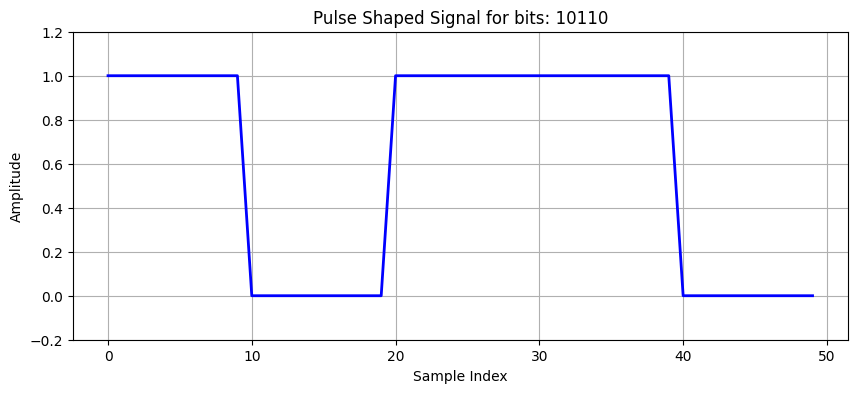

In [11]:
# ---------------------------------------------------------
# Part 2.7 - Pulse Shaping
# ---------------------------------------------------------

def Pulse_Shaping(bit_sequence, pulse_shape):
    """
    Converts a bit sequence into a continuous-time signal (sampled).
    
    Args:
        bit_sequence (str or list): Sequence of 0s and 1s.
        pulse_shape (np.array): The discrete samples of the basic pulse shape g(t).
        
    Returns:
        np.array: The concatenated signal.
    """
    # Convert input to numeric if it's a string
    bits = [int(b) for b in bit_sequence]
    
    # In simple Pulse Shaping, we replace each '1' with pulse_shape 
    # and each '0' with a zero-amplitude pulse of the same length 
    # (assuming Unipolar signaling for now, or you can map 0 to -pulse_shape for Polar).
    
    signal_chunks = []
    for bit in bits:
        if bit == 1:
            signal_chunks.append(pulse_shape)
        else:
            # For 0: either zero voltage or negative pulse (depending on modulation)
            # Here we use zero voltage as a general case:
            signal_chunks.append(np.zeros_like(pulse_shape))
            
    # Concatenate all pulse periods into one continuous signal
    continuous_signal = np.concatenate(signal_chunks)
    
    return continuous_signal

# ---------------------------------------------------------
# Testing and Visualization
# ---------------------------------------------------------

# 1. Define a simple rectangular pulse (e.g., 10 samples per bit)
samples_per_bit = 10
rect_pulse = np.ones(samples_per_bit)

# 2. Test bit sequence
test_bits = "10110"

# 3. Generate Signal
generated_signal = Pulse_Shaping(test_bits, rect_pulse)

print(f"Input Bits: {test_bits}")
print(f"Pulse Length: {len(rect_pulse)} samples")
print(f"Total Signal Length: {len(generated_signal)} samples")

# 4. Plotting for Report
plt.figure(figsize=(10, 4))
plt.plot(generated_signal, 'b', linewidth=2)
plt.title(f"Pulse Shaped Signal for bits: {test_bits}")
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.grid(True)
plt.ylim(-0.2, 1.2)
plt.show()

### Question 2 :
Write a function called AnalogMod that receives as input the sampled waveform and the carrier frequency, and produces the modulated signal $x_c (t)$ at the output.

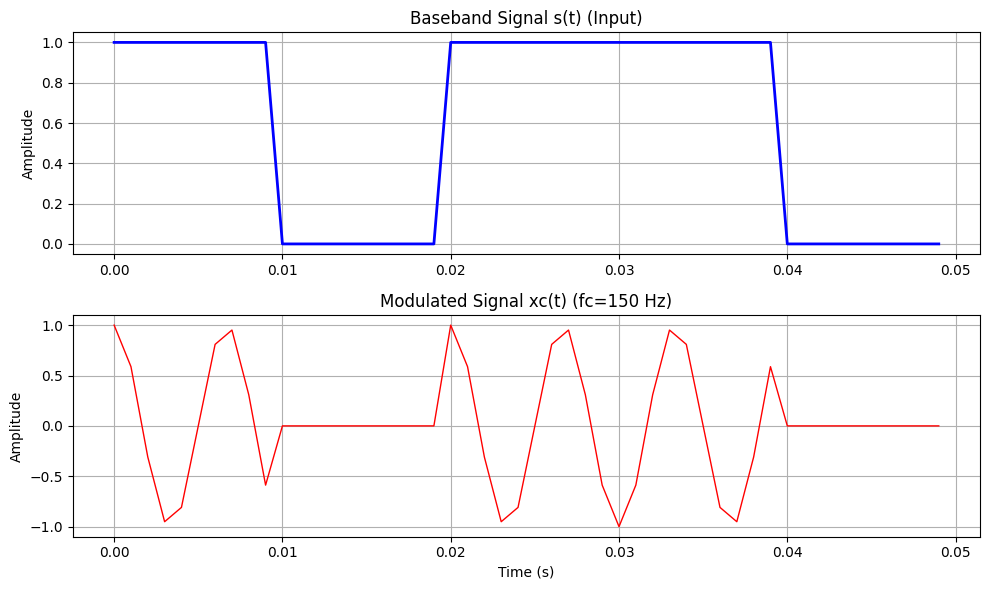

In [12]:
# ---------------------------------------------------------
# Part 2.7 - Question 2: Analog Modulation
# ---------------------------------------------------------

def Analog_Mod(baseband_signal, carrier_freq, fs):
    """
    Modulates the baseband signal onto a carrier frequency.
    
    Args:
        baseband_signal (np.array): The pulse-shaped signal s(t).
        carrier_freq (float): The carrier frequency (fc) in Hz.
        fs (float): Sampling frequency in Hz (samples per second).
        
    Returns:
        np.array: The modulated signal xc(t).
        np.array: The time vector t (useful for plotting).
    """
    # 1. Create Time Vector
    # Time steps are 1/fs. Total duration = number of samples / fs.
    num_samples = len(baseband_signal)
    t = np.arange(num_samples) / fs
    
    # 2. Generate Carrier Wave
    # c(t) = cos(2 * pi * fc * t)
    carrier_wave = np.cos(2 * np.pi * carrier_freq * t)
    
    # 3. Modulate (Multiply)
    # xc(t) = s(t) * c(t)
    modulated_signal = baseband_signal * carrier_wave
    
    return modulated_signal, t

# ---------------------------------------------------------
# Testing and Visualization
# ---------------------------------------------------------

# Parameters
fs = 1000       # Sampling frequency (1000 Hz)
fc = 150         # Carrier frequency (150 Hz)
# Let's use the 'generated_signal' from the previous question as input
# Perform Modulation
xc_t, t_vec = Analog_Mod(generated_signal, fc, fs)

# Plotting
plt.figure(figsize=(10, 6))

# Plot Baseband Signal
plt.subplot(2, 1, 1)
plt.plot(t_vec, generated_signal, 'b', linewidth=2)
plt.title("Baseband Signal s(t) (Input)")
plt.ylabel("Amplitude")
plt.grid(True)

# Plot Modulated Signal
plt.subplot(2, 1, 2)
plt.plot(t_vec, xc_t, 'r', linewidth=1)
plt.title(f"Modulated Signal xc(t) (fc={fc} Hz)")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.grid(True)

plt.tight_layout()
plt.show()

### Question 3 :
Write a function called AnalogDemod that takes as input the signal $x_c (t)$, the sampling frequency, the signal bandwidth, and the carrier frequency, and outputs two demodulated waveforms, namely $y_I (t)$ and $y_Q (t)$ (using multiplication and low-pass filtering).

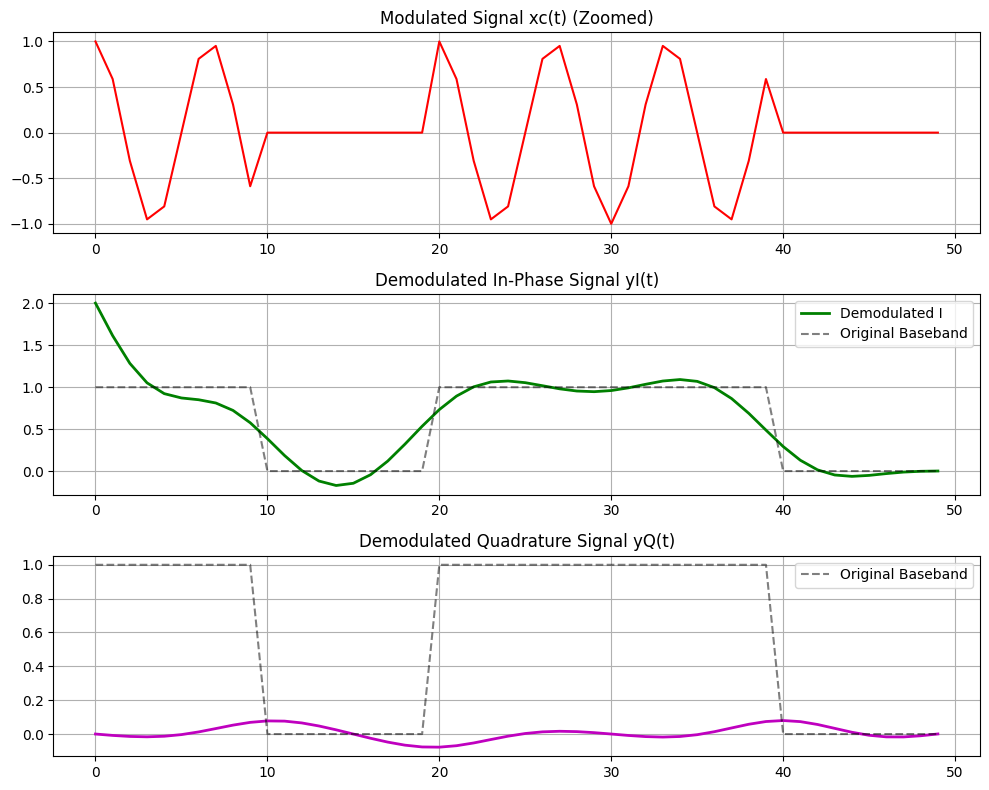

In [13]:
# ---------------------------------------------------------
# Part 2.7 - Question 3: Analog Demodulation
# ---------------------------------------------------------

def AnalogDemod(xc_t, fc, fs, bw):
    """
    Demodulates the signal using mixing and low-pass filtering.
    
    Args:
        xc_t (np.array): The modulated signal (received signal).
        fc (float): Carrier frequency in Hz.
        fs (float): Sampling frequency in Hz.
        bw (float): Bandwidth of the baseband signal (cutoff frequency for LPF).
        
    Returns:
        np.array: yI(t) - The In-phase component.
        np.array: yQ(t) - The Quadrature component.
    """
    # 1. Create Time Vector
    num_samples = len(xc_t)
    t = np.arange(num_samples) / fs
    
    # 2. Mixing (Down-conversion)
    # Multiply by local carrier: cos(wt) and -sin(wt)
    mixed_I = xc_t * np.cos(2 * np.pi * fc * t)
    mixed_Q = xc_t * -np.sin(2 * np.pi * fc * t) # Standard IQ definition
    
    # 3. Low-Pass Filtering
    # Design a Butterworth Low-Pass Filter
    # Nyquist frequency is fs / 2
    nyquist = 0.5 * fs
    normal_cutoff = bw / nyquist
    
    # Create filter coefficients (Order 5 is usually sufficient)
    b, a = signal.butter(5, normal_cutoff, btype='low', analog=False)
    
    # Apply filter (filtfilt is used to avoid phase shift/delay)
    yI_t = signal.filtfilt(b, a, mixed_I) * 2 # Multiply by 2 to recover amplitude
    yQ_t = signal.filtfilt(b, a, mixed_Q) * 2
    
    return yI_t, yQ_t

# ---------------------------------------------------------
# Testing and Visualization
# ---------------------------------------------------------

# Using parameters from previous step
# fs = 1000, fc = 50, xc_t = modulated signal from Q2
# We need to define Bandwidth (bw). 
# For a rectangular pulse of length T, BW is roughly 1/T.
# In previous code, pulse length was 10 samples at 1000Hz -> T = 0.01s -> BW ~ 100Hz
# However, let's use a slightly wider BW to preserve edges, e.g., 150Hz.

bw = 100 # Cutoff frequency for LPF

# Perform Demodulation
demod_I, demod_Q = AnalogDemod(xc_t, fc, fs, bw)
    
# Visualization
plt.figure(figsize=(10, 8))
    
# Original Modulated
plt.subplot(3, 1, 1)
plt.plot(xc_t[:200], 'r') # Zoom in on first 200 samples
plt.title("Modulated Signal xc(t) (Zoomed)")
plt.grid(True)
    
# Demodulated I (In-phase)
plt.subplot(3, 1, 2)
plt.plot(demod_I, 'g', linewidth=2, label='Demodulated I')
# Plot original baseband on top for comparison
plt.plot(generated_signal, 'k--', alpha=0.5, label='Original Baseband')
plt.title("Demodulated In-Phase Signal yI(t)")
plt.legend()
plt.grid(True)
    
# Demodulated Q (Quadrature)
plt.subplot(3, 1, 3)
plt.plot(demod_Q, 'm', linewidth=2)
plt.plot(generated_signal, 'k--', alpha=0.5, label='Original Baseband')
plt.title("Demodulated Quadrature Signal yQ(t)")
plt.legend()
plt.grid(True)
    
plt.tight_layout()
plt.show()


## FSK Modulation
    In this section, we want to transmit signals using FSK modulation. Note that in this project, the signals are transmitted in the form of two-bit symbols (00,01,10,11). Select four orthogonal frequencies according to the modulation specifications.
### Part a :
Generate a sequence of length L (sufficiently large) from the alphabet in Table 1, and convert it into a binary sequence of 0s and 1s using the functions source_coder and Hamming_coder.

In [14]:
# ---------------------------------------------------------
# 1. Parameter Definition
# ---------------------------------------------------------
fs = 1e6           # 1 MHz Sampling Rate
T_sym = 10e-3      # 10 ms Pulse Duration
fc = 10e3          # 10 kHz Carrier Frequency
BW = 1e3           # 1 kHz Channel Bandwidth

# Calculated Frequencies for 4-FSK
freqs = {
    '00': fc - 150,  # 9850 Hz
    '01': fc - 50,   # 9950 Hz
    '10': fc + 50,   # 10050 Hz
    '11': fc + 150   # 10150 Hz
}
print(f"--- FSK Modulation ---")
print("--- Selected Orthogonal Frequencies ---")
for bits, f in freqs.items():
    print(f"Symbol {bits}: {f:.0f} Hz")
print("-" * 30)


# ---------------------------------------------------------
# 2. Main Execution 
# ---------------------------------------------------------

# Table 1 Probabilities
symbols_list = ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J']
weights = [0.25, 0.20, 0.15, 0.10, 0.08, 0.07, 0.05, 0.04, 0.04, 0.02]
prob_dict = dict(zip(symbols_list, weights))

# A) Generate a long sequence (L symbols)
L = 150  # Length of symbol sequence
source_string = generate_data(L)

# B) Apply Source Coding (Huffman)
huffman_dict = Huffman_code(prob_dict)
huffman_bits = source_coder(source_string, huffman_dict)

# C) Apply Channel Coding (Hamming)
final_bits = Hamming_coder(huffman_bits)

# D) Prepare for 4-FSK (Ensure even length)
# Since 4-FSK takes 2 bits per symbol, total bits must be even.
if len(final_bits) % 2 != 0:
    final_bits += '0'

# ---------------------------------------------------------
# 3. Results & Verification
# ---------------------------------------------------------

print(f"\n--- Data Generation & Coding Results ---")
print(f"1. Original Sequence (L={L}): {source_string[:15]}...")
print(f"2. Huffman Encoded Bits:      {huffman_bits[:20]}... (Total Len: {len(huffman_bits)})")
print(f"3. Hamming Encoded Bits:      {final_bits[:20]}... (Total Len: {len(final_bits)})")
print(f"4. Total 4-FSK Symbols:       {len(final_bits)//2}")

# Calculate Expected Duration of Signal
total_duration = (len(final_bits) / 2) * T_sym
print(f"5. Expected Signal Duration:  {total_duration:.4f} seconds")

--- FSK Modulation ---
--- Selected Orthogonal Frequencies ---
Symbol 00: 9850 Hz
Symbol 01: 9950 Hz
Symbol 10: 10050 Hz
Symbol 11: 10150 Hz
------------------------------

--- Data Generation & Coding Results ---
1. Original Sequence (L=150): BEACBBJFCBACABA...
2. Huffman Encoded Bits:      00111010110000001100... (Total Len: 423)
3. Hamming Encoded Bits:      10000111011010011110... (Total Len: 742)
4. Total 4-FSK Symbols:       371
5. Expected Signal Duration:  3.7100 seconds


### Part b:
Using the pulse_shaping function and four orthogonal signals, convert this bitstream into a signal that is ready to be modulated by Analog_mod. Now, assuming that AWGN noise is added to the signal after it passes through the channel, plot the probability of error versus the noise variance. Choose a sufficiently wide range for the horizontal axis. Pay close attention to the behavior of the error probability. Consider $σ^2$ in steps of 30, within the range:
$$ 30≤σ≤180$$


Generating FSK Signal...
Signal Generated. Length: 3710000 samples.

Starting Noise Simulation with 10 km Channel...
Variance   Sigma      Bit Errors   BER       
---------------------------------------------
30         5.48       16           0.0216    
60         7.75       78           0.1051    
90         9.49       148          0.1995    
120        10.95      161          0.2170    
150        12.25      210          0.2830    
180        13.42      227          0.3059    


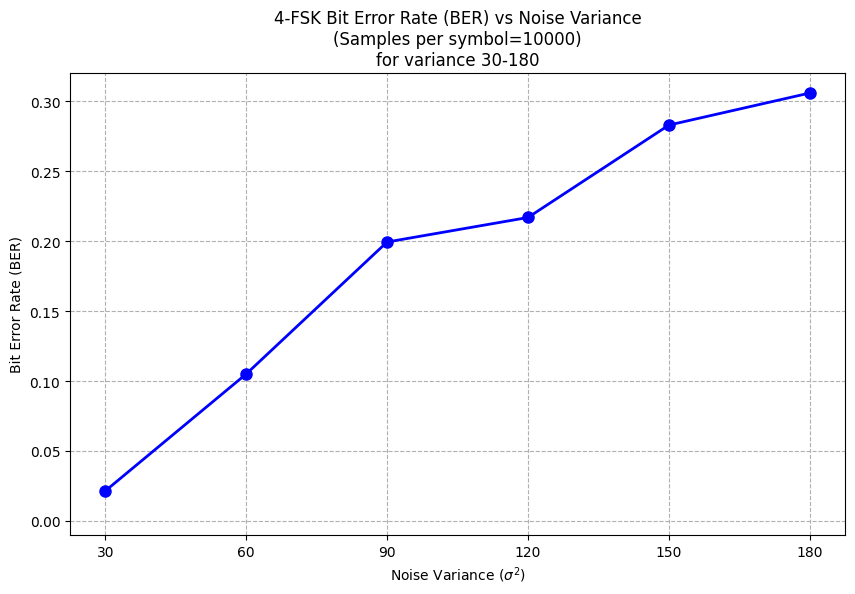

In [72]:
# ---------------------------------------------------------
# Part (b) - FSK Modulation & Error Analysis
# ---------------------------------------------------------

# --- 1. Setup Parameters ---
samples_per_sym = int(T_sym * fs)

# Map index (0-3) to bit pairs for decoding
idx_to_bits = ['00', '01', '10', '11']
frequencies = [freqs[b] for b in idx_to_bits]

# --- 2. Transmitter: Generate 4-FSK Signal ---

# Group bits into 2-bit symbols
symbols = [final_bits[i:i+2] for i in range(0, len(final_bits), 2)]
num_symbols = len(symbols)

# Pulse shape is a rectangular window of ones
pulse = np.ones(samples_per_sym)

# Create 4 parallel streams (One-Hot Encoding for FSK branches)
streams = {key: [] for key in idx_to_bits}

for sym in symbols:
    for key in idx_to_bits:
        if sym == key:
            streams[key].append(1)  # Transmit pulse
        else:
            streams[key].append(0)  # Transmit silence

# Modulate and sum all branches
tx_signal = np.zeros(num_symbols * samples_per_sym)
t_full = np.arange(len(tx_signal)) / fs

print("Generating FSK Signal...")
for key in idx_to_bits:
    # 1. Pulse shaping for this frequency branch
    # Using the defined Pulse_Shaping function
    branch_bits = streams[key]
    baseband = Pulse_Shaping(branch_bits, pulse)
    
    # 2. Analog modulation
    # Analog_Mod generates its own time vector, which is fine
    mod_signal, _ = Analog_Mod(baseband, freqs[key], fs)
    
    # Sum all modulated branches together
    tx_signal += mod_signal

print(f"Signal Generated. Length: {len(tx_signal)} samples.")

# --- 3. Noise Loop & Error Calculation ---
variances = np.arange(30, 181, 30)  # 30, 60, 90, 120, 150, 180
error_rates = []

# --- Channel distance parameter ---
distance_km = 10 

print(f"\nStarting Noise Simulation with {distance_km} km Channel...")
print(f"{'Variance':<10} {'Sigma':<10} {'Bit Errors':<12} {'BER':<10}")
print("-" * 45)

# Run the loop for each variance value
for var in variances:
    sigma = np.sqrt(var)
    
    # --- (a) Channel model and noise ---
    # 1. Apply channel attenuation before reaching the receiver
    rx_attenuated, gain = Channel_Model(tx_signal, distance_km)
    
    # 2. Apply channel noise
    rx_signal = apply_noise(rx_attenuated, sigma)
    
    # --- (b) Demodulator (Correlator Bank) ---
    rx_chunks = rx_signal.reshape(num_symbols, samples_per_sym)
    t_sym = np.arange(samples_per_sym) / fs
    detected_bits = ""
    
    # --- Non-Coherent Receiver ---
    for chunk in rx_chunks:
        energies = []
        for f_target in frequencies:
            # Correlation with I and Q components
            ref_I = np.cos(2 * np.pi * f_target * t_sym)
            ref_Q = np.sin(2 * np.pi * f_target * t_sym)
            
            corr_I = np.sum(chunk * ref_I)
            corr_Q = np.sum(chunk * ref_Q)
            
            # Compute non-coherent energy
            energy = corr_I**2 + corr_Q**2
            energies.append(energy)
        
        # Select the frequency with the highest energy
        best_idx = np.argmax(energies)
        detected_bits += idx_to_bits[best_idx]
        
    # --- (c) Error calculation ---
    bit_errors = sum(c1 != c2 for c1, c2 in zip(final_bits, detected_bits))
    ber = bit_errors / len(final_bits)
    error_rates.append(ber)
    
    print(f"{var:<10} {sigma:<10.2f} {bit_errors:<12} {ber:<10.4f}")

# --- 4. Plotting ---

plt.figure(figsize=(10, 6))
plt.plot(variances, error_rates, 'bo-', linewidth=2, markersize=8)
plt.title(f'4-FSK Bit Error Rate (BER) vs Noise Variance\n'
          f'(Samples per symbol={samples_per_sym})\n'
          f'for variance 30-180')
plt.xlabel('Noise Variance ($\sigma^2$)')
plt.ylabel('Bit Error Rate (BER)')
plt.grid(True, which='both', linestyle='--')
plt.xticks(variances)
plt.ylim(bottom=-0.01)
plt.show()


### Part c :
Based on the previous section, select six different values for the noise variance. For each of these variance values, plot the two-dimensional scatter plot of the outputs of the four matched filters
$(\hat{b}_I[i], \hat{b}_Q[i])$
.
When the noise variance is small, the points are estimated correctly. However, as the noise variance increases, these points become more dispersed. Plot these points on a graph and compare the diagrams for different variance values.
This task conceptually represents the Signal Constellation of the system.


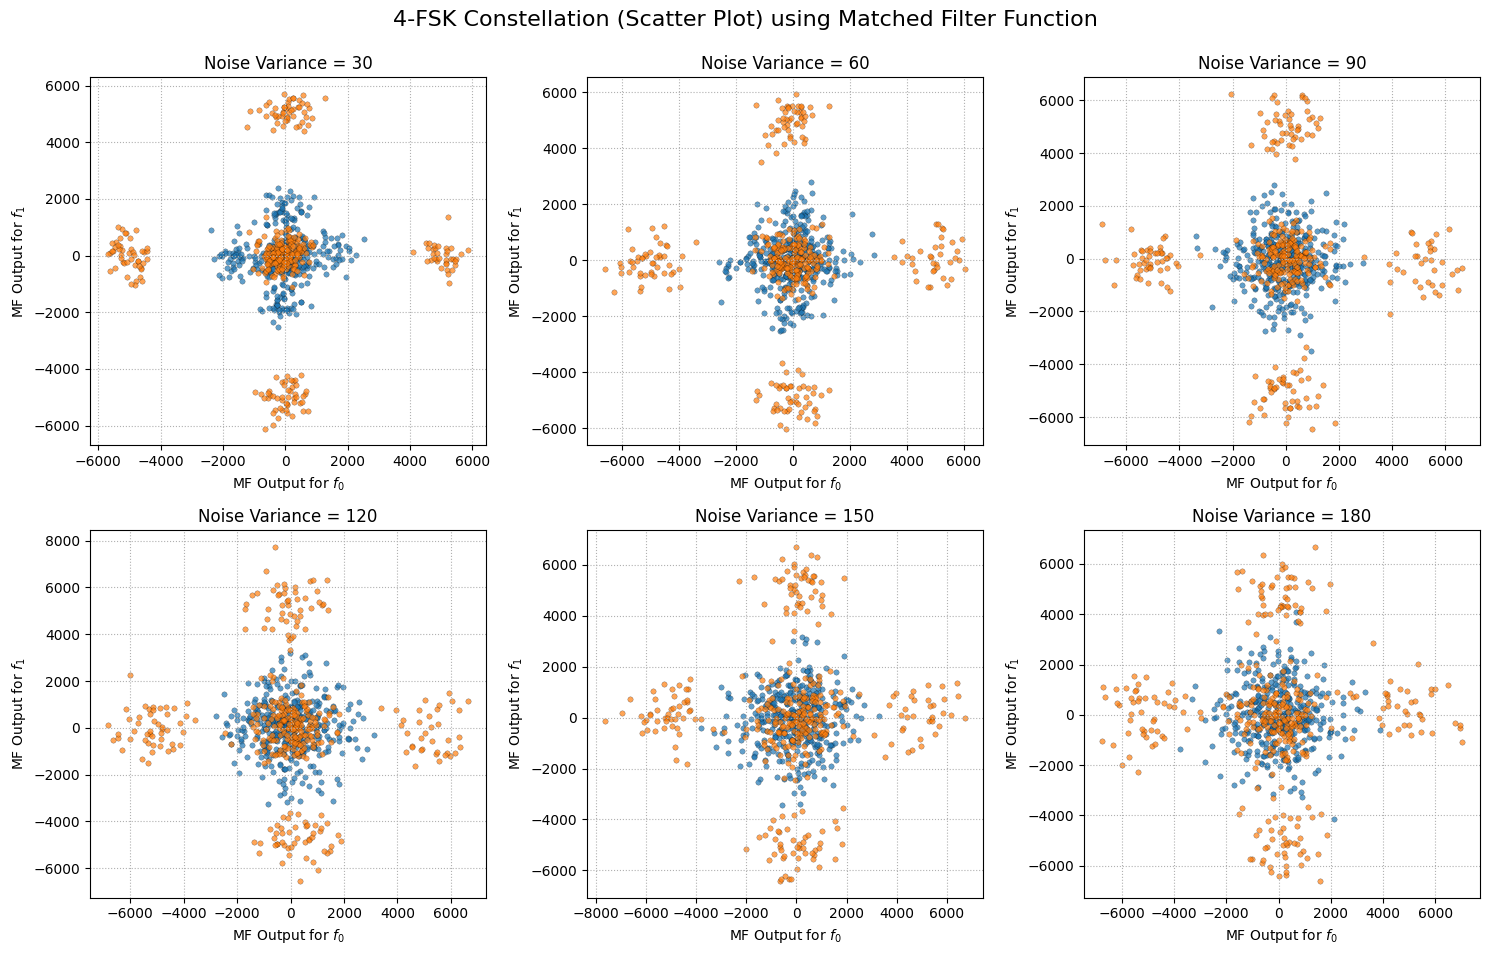

In [16]:
# --------------------------------------------------------------
# Part (c) - Scatter Plot of the output of Matched Filter 
# --------------------------------------------------------------

# --- 1. Settings and Variables ---
variances = [30, 60, 90, 120, 150, 180]
t_sym = np.arange(samples_per_sym) / fs
# Reference pulses for the 4 frequencies
pulse_refs = [np.cos(2 * np.pi * f * t_sym) for f in frequencies]

plt.figure(figsize=(15, 10))

for i, var in enumerate(variances):
    sigma = np.sqrt(var)
    rx_attenuated, gain = Channel_Model(tx_signal, distance_km)
    rx_signal_attenuated = apply_noise(rx_attenuated, sigma)
    rx_signal = apply_noise(tx_signal, sigma)

    # Output of the matched filters for the entire signal
    # We apply the filter for the first and second frequencies
    mf0_full_attenuated = Matched_Filter(rx_signal_attenuated, pulse_refs[0])
    mf1_full_attenuated = Matched_Filter(rx_signal_attenuated, pulse_refs[1])
    mf0_full = Matched_Filter(rx_signal, pulse_refs[0])
    mf1_full = Matched_Filter(rx_signal, pulse_refs[1])
    
    # --- 2. Sampling ---
    # Since the pulse length is samples_per_sym, the convolution peak
    # occurs at multiples of this length (considering filter delay).
    f0_samples_attenuated = []
    f1_samples_attenuated = []
    f0_samples = []
    f1_samples = []
    
    for k in range(num_symbols):
        # Optimal sampling instant: end of each symbol
        sample_idx = (k + 1) * samples_per_sym - 1
        
        # Extract the value at that instant
        f0_samples_attenuated.append(mf0_full_attenuated[sample_idx])
        f1_samples_attenuated.append(mf1_full_attenuated[sample_idx])
        f0_samples.append(mf0_full[sample_idx])
        f1_samples.append(mf1_full[sample_idx])
    
    # --- 3. Plotting ---
    plt.subplot(2, 3, i+1)
    plt.scatter(f0_samples_attenuated, f1_samples_attenuated, alpha=0.7, s=15, edgecolors='k', linewidths=0.2)
    plt.title(f'Noise Variance = {var}')
    plt.xlabel('MF Output for $f_0$')
    plt.ylabel('MF Output for $f_1$')
    plt.grid(True, linestyle=':')

    plt.subplot(2, 3, i+1)
    plt.scatter(f0_samples, f1_samples, alpha=0.7, s=15, edgecolors='k', linewidths=0.2)
    plt.title(f'Noise Variance = {var}')
    plt.xlabel('MF Output for $f_0$')
    plt.ylabel('MF Output for $f_1$')
    plt.grid(True, linestyle=':')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.suptitle('4-FSK Constellation (Scatter Plot) using Matched Filter Function', fontsize=16)
plt.show()


### Part d :
Plot the eye diagram of the received signal for different noise variance values and analyze its fundamental components.

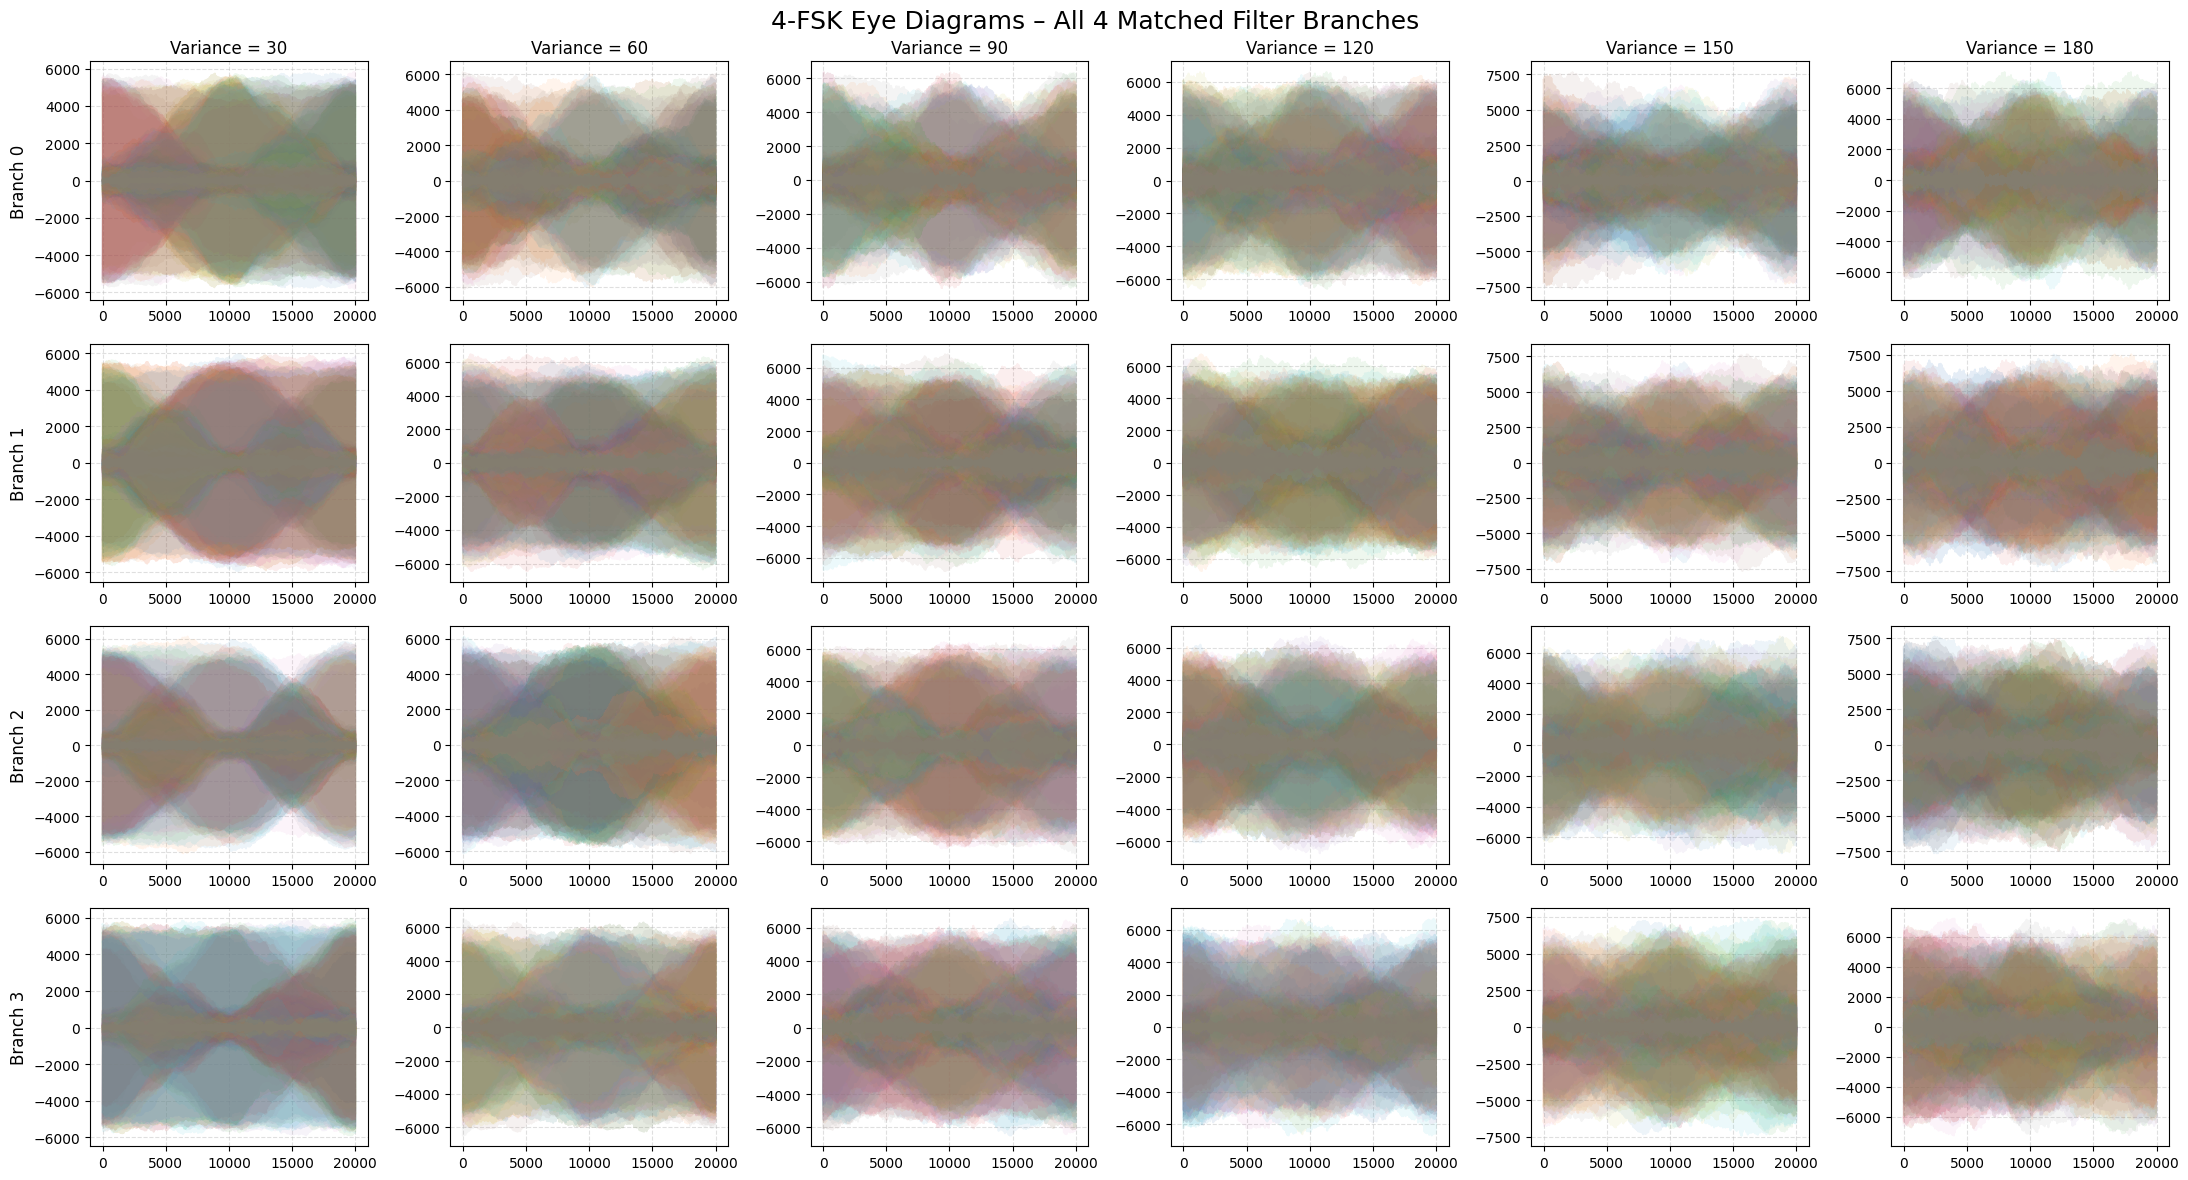

In [17]:
# --------------------------------------
# Part (d) - 4-FSK Eye Diagram (All Branches)
# --------------------------------------

# --- Parameters ---
variances = [30, 60, 90, 120, 150, 180]
samples_to_show = 2 * samples_per_sym      # show two symbols
num_traces = 100                           # number of overlapped traces
num_branches = len(pulse_refs)             # for 4-FSK

plt.figure(figsize=(22, 12))

for col, var in enumerate(variances):

    # 1.Add noise
    sigma = np.sqrt(var)
    rx_signal = apply_noise(tx_signal, sigma)

    # 2.Matched filter outputs for all branches
    mf_outputs = []

    for p in pulse_refs:
        mf = Matched_Filter(rx_signal, p)

        # Compensate for matched filter delay
        delay = len(p) - 1
        mf = mf[delay:]

        mf_outputs.append(mf)

    # 3.Plot eye diagram for each branch
    for row in range(num_branches):

        plt.subplot(num_branches, len(variances),
                    row * len(variances) + col + 1)

        mf_out = mf_outputs[row]

        max_segments = len(mf_out) // samples_per_sym - 2

        for _ in range(num_traces):

            # Random segment selection (better eye)
            k = np.random.randint(0, max_segments)
            start = k * samples_per_sym
            end = start + samples_to_show

            if end < len(mf_out):
                plt.plot(mf_out[start:end], alpha=0.08)

        if row == 0:
            plt.title(f'Variance = {var}', fontsize=12)

        if col == 0:
            plt.ylabel(f'Branch {row}', fontsize=12)

        plt.grid(True, linestyle='--', alpha=0.4)

plt.suptitle('4-FSK Eye Diagrams – All 4 Matched Filter Branches',
             fontsize=18)

plt.tight_layout()
plt.show()


## Testing for 4-FSK

In [32]:

# =====================================================================#
# Connecting all the Blocks and Testing it with a 150-letter string    #
# =====================================================================#


# ==========================================
# Defining Hamming Decoder 
# ==========================================
def Hamming_decoder(encoded_bits):
    decoded_bits = ""
    n_blocks = len(encoded_bits) // 7
    for i in range(n_blocks):
        block = encoded_bits[i*7 : (i+1)*7]
        r = [int(b) for b in block]
        s1 = r[0] ^ r[2] ^ r[4] ^ r[6]
        s2 = r[1] ^ r[2] ^ r[5] ^ r[6]
        s3 = r[3] ^ r[4] ^ r[5] ^ r[6]
        syndrome_idx = s3 * 4 + s2 * 2 + s1
        if syndrome_idx > 0:
            error_pos = syndrome_idx - 1
            r[error_pos] = 1 - r[error_pos]
        decoded_bits += f"{r[2]}{r[4]}{r[5]}{r[6]}"
    return decoded_bits


# ==========================================
# Main Processing Pipeline
# ==========================================

# --- A. Configuration ---
fs = 1e6           # 1 MHz
T_sym = 10e-3      # 10 ms
fc = 10e3          # 10 kHz
channel_length_km = 10  # Distance in km
noise_variance = 30      #  Variance

samples_per_sym = int(T_sym * fs)

# 4-FSK Frequencies
# Orthogonal spacing: multiples of 100 Hz
freq_map = {
    '00': fc - 100,
    '01': fc - 50,
    '10': fc + 50,
    '11': fc + 100
}

freq_to_bits = {v: k for k, v in freq_map.items()}
sorted_freqs = sorted(freq_map.values())

# --- B. Data Generation & Source/Channel Coding ---
L = 150 
original_text = generate_data(L)

# Huffman
prob_dict = {'A': 0.25, 'B': 0.20, 'C': 0.15, 'D': 0.10, 'E': 0.08, 
             'F': 0.07, 'G': 0.05, 'H': 0.04, 'I': 0.04, 'J': 0.02}
huff_dict = Huffman_code(prob_dict)
huff_bits = source_coder(original_text, huff_dict)

# Hamming (7,4)
hamm_bits = Hamming_coder(huff_bits)
if len(hamm_bits) % 2 != 0: hamm_bits += '0' # Pad for 4-FSK

# --- C. FSK Modulation ---
print("1. Modulating Signal...")
tx_signal = np.zeros(len(hamm_bits)//2 * samples_per_sym)
bit_pairs = [hamm_bits[i:i+2] for i in range(0, len(hamm_bits), 2)]
pulse = np.ones(samples_per_sym)
num_symbols = len(hamm_bits) // 2
# Store original branches for Matched Filter references
reference_pulses = {} 
for pair, freq in freq_map.items():
    t_single = np.arange(samples_per_sym) / fs
    # The reference for the matched filter is the carrier at that frequency
    reference_pulses[pair] = np.cos(2 * np.pi * freq * t_single)

for pair in ['00', '01', '10', '11']:
    stream = [1 if bp == pair else 0 for bp in bit_pairs]
    baseband = Pulse_Shaping(stream, pulse)
    mod_branch, t_vec = Analog_Mod(baseband, freq_map[pair], fs)
    tx_signal += mod_branch

# --- D. Channel (Attenuation + Noise) ---
tx_attenuated, gain = Channel_Model(tx_signal, channel_length_km)
sigma = np.sqrt(noise_variance)
rx_signal = apply_noise(tx_attenuated, sigma)


# --- E. Matched Filtering ---
print("2. Applying Matched Filter Bank...")
# We create a filtered output for each of the 4 possible frequencies
mf_outputs = {}
for pair in ['00', '01', '10', '11']:
    # Match the received signal against the expected pulse shape for each frequency
    mf_outputs[pair] = Matched_Filter(rx_signal, reference_pulses[pair])

# --- F. Demodulation (AnalogDemod) ---
print("3. Discriminator Demodulating (AnalogDemod)...")
yI, yQ = AnalogDemod(rx_signal, fc, fs, bw=500)
inst_phase = np.unwrap(np.angle(yI + 1j * yQ))
inst_freq_dev = (np.diff(inst_phase) / (2.0*np.pi) * fs)
inst_freq_dev = np.append(inst_freq_dev, inst_freq_dev[-1])

# --- G. Detection (Using Matched Filter Peaks) ---
print("4. Detecting Symbols...")
sampling_indices = (np.arange(1, num_symbols + 1) * samples_per_sym) - 1
energy = np.sum(pulse**2)

detected_bits = ""

for i in range(num_symbols):
    idx = sampling_indices[i]
    
    metrics = {}
    for pair in freq_map:
        metrics[pair] = mf_outputs[pair][idx] / energy
    
    best_pair = max(metrics, key=lambda k: abs(metrics[k]))
    detected_bits += best_pair

# --- H. Decoding ---
print("5. Decoding...")
decoded_hamming = Hamming_decoder(detected_bits)
final_text = source_decoder(decoded_hamming, huff_dict)


# --- H. Results ---
print("\n" + "="*50)
print(f"RESULTS (Dist: {channel_length_km}km, Noise Var: {noise_variance})")
print("="*50)

# Calculate Bit Error Rate (BER)
errors = sum(c1 != c2 for c1, c2 in zip(hamm_bits, detected_bits))
ber = errors / len(hamm_bits)

print(f"Transmission Gain:      {gain:.4f} (-{channel_length_km:.1f} dB)")
print(f"Raw Bit Errors:         {errors} / {len(hamm_bits)}")
print(f"Raw BER:                {ber:.4f}")
print("-" * 50)
print(f"Original Text (head):   {original_text[:40]}...")
print(f"Recovered Text (head):  {final_text[:40]}...")




1. Modulating Signal...
2. Applying Matched Filter Bank...
3. Discriminator Demodulating (AnalogDemod)...
4. Detecting Symbols...
5. Decoding...

RESULTS (Dist: 10km, Noise Var: 30)
Transmission Gain:      0.3162 (-10.0 dB)
Raw Bit Errors:         6 / 798
Raw BER:                0.0075
--------------------------------------------------
Original Text (head):   BFEEEDBBADHCABBABFACACACCACCAACEDABEAGBH...
Recovered Text (head):  BFEEEDBBADHCABBABFACACACCACCAACEDABEAGBH...


## QPSK Modulation
    In this section, we want to change our modulation to QPSK. Explain theoretically how the signals used for each pair of bits are selected.
### Part a :
Generate a sequence of length L (sufficiently large) from the alphabet in Table 1, and convert it into a binary sequence of 0s and 1s using the functions source_coder and Hamming_coder.

In [23]:
# ---------------------------------------------------------
# 1. Main Execution 
# ---------------------------------------------------------

# Table 1 Probabilities
# A) Generate a long sequence L
L = 150
source_sequence = generate_data(L)

# Define Probabilities
prob_dict = {
    'A': 0.25, 'B': 0.20, 'C': 0.15, 'D': 0.10, 'E': 0.08,
    'F': 0.07, 'G': 0.05, 'H': 0.04, 'I': 0.04, 'J': 0.02
}

# B) Apply Source Coding
huff_codes = Huffman_code(prob_dict)
huffman_bits = source_coder(source_sequence, huff_codes)

# C) Apply Channel Coding
hamming_bits = Hamming_coder(huffman_bits)

# D) Prepare for QPSK (Ensure even length)
# QPSK takes 2 bits per symbol, so total bits must be even.
if len(hamming_bits) % 2 != 0:
    hamming_bits += '0'

# ---------------------------------------------------------
# 2. Results & Verification
# ---------------------------------------------------------
print(f"--- QPSK Part (a): Data Generation ---")
print(f"1. Original Sequence Bits(L={L}): {source_sequence[:15]}...")
print(f"2. Huffman Encoded Bits: {huffman_bits[:20]}... (Total Len: {len(huffman_bits)})")
print(f"3. Hamming Encoded Bits: {hamming_bits[:20]}... (Total Len: {len(hamming_bits)})")


--- QPSK Part (a): Data Generation ---
1. Original Sequence Bits(L=150): AABHFADFJEACBAA...
2. Huffman Encoded Bits: 10100001101011110010... (Total Len: 449)
3. Hamming Encoded Bits: 10110101101001101101... (Total Len: 792)


### Part b:
Using the pulse_shaping functions and the four signal waveforms, convert the bit stream into a single signal that is ready to be modulated by Analog_mod. Now, assuming that AWGN noise is added to the signal after it passes through the channel, plot the error probability as a function of the noise variance. Choose a sufficiently large range for the horizontal axis. Pay attention to the behavior of the error probability. Consider $σ^2$ with step sizes of 30, and vary the noise variance from $σ^2=30$ up to $σ^2=180$.


--- Starting QPSK Noise Analysis ---
Variance:  30 | Sigma: 5.48 | Errors:   1 | BER: 0.0013
Variance:  60 | Sigma: 7.75 | Errors:   1 | BER: 0.0013
Variance:  90 | Sigma: 9.49 | Errors:  15 | BER: 0.0189
Variance: 120 | Sigma: 10.95 | Errors:  19 | BER: 0.0240
Variance: 150 | Sigma: 12.25 | Errors:  25 | BER: 0.0316
Variance: 180 | Sigma: 13.42 | Errors:  42 | BER: 0.0530


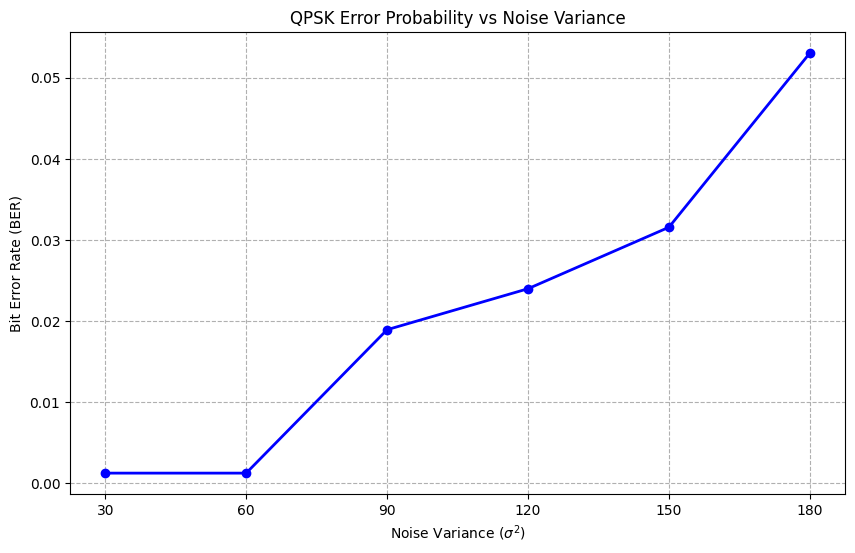

In [75]:
# ---------------------------------------------
# PART (b): QPSK Modulation & Noise Analysis
# ---------------------------------------------

# --- 1. System Parameters ---
fs = 1e6              # Sampling Frequency: 1 MHz
fc = 10e3             # Carrier Frequency: 10 kHz
T_duration = 0.01     # Pulse Duration: 10 ms
length_km = 10       # Distance for Channel 
bw_baseband = 500     # Bandwidth for Demod LPF (Hz)

# Calculate samples per pulse
samples_per_pulse = int(T_duration * fs)
pulse_shape = np.ones(samples_per_pulse) # Rectangular pulse

# --- 2. QPSK Transmitter (Modulation) ---

# A) Split bits into I (In-phase) and Q (Quadrature) streams
# hamming_bits is a string of '0's and '1's
bits_I = hamming_bits[0::2] # Even indices
bits_Q = hamming_bits[1::2] # Odd indices

# B) Pulse Shaping (Baseband)
# Note: Pulse_Shaping function maps 1->Pulse, 0->0.
# For QPSK, we need Bipolar mapping: 0 -> -1, 1 -> +1.
# We convert the unipolar (0,1) output to bipolar (-1,1) mathematically: 
# Signal_Bipolar = 2 * Signal_Unipolar - 1
sig_I_unipolar = Pulse_Shaping(bits_I, pulse_shape)
sig_Q_unipolar = Pulse_Shaping(bits_Q, pulse_shape)

sig_I = 2 * sig_I_unipolar - 1
sig_Q = 2 * sig_Q_unipolar - 1

# C) Analog Modulation
# Branch I: Modulate with Cosine 
mod_I, t = Analog_Mod(sig_I, fc, fs)

# Branch Q: Modulate with -Sine
# Since Analog_Mod uses Cosine, we generate the sine carrier manually using the same 't'
carrier_sin = np.sin(2 * np.pi * fc * t)
mod_Q = sig_Q * (-carrier_sin) # Standard QPSK definition: I*cos - Q*sin

# Total Transmitted Signal
tx_signal = mod_I + mod_Q

# --- 3. Noise Loop & Analysis ---

variance_values = range(30, 181, 30) # 30, 60, ..., 180
ber_results = []

print("\n--- Starting QPSK Noise Analysis ---")

for var in variance_values:
    sigma = np.sqrt(var) # Standard deviation is sqrt of variance
    
    # A) Channel Transmission (Attenuation)
    rx_attenuated, _ = Channel_Model(tx_signal, length_km)
    
    # B) Add Noise (AWGN)
    rx_noisy = apply_noise(rx_attenuated, sigma)
    
    # C) Demodulation
    # AnalogDemod returns the baseband I and Q components
    yI_rec, yQ_rec = AnalogDemod(rx_noisy, fc, fs, bw_baseband)
    
    # D) Matched Filtering
    # Convolve received baseband with the matched pulse
    filt_I = Matched_Filter(yI_rec, pulse_shape)
    filt_Q = Matched_Filter(yQ_rec, pulse_shape)
    
    # E) Sampling & Decision
    # We sample at the end of each pulse period. 
    # Convolution 'full' mode peaks occur at indices: N-1, 2N-1, ...
    num_symbols = len(bits_I)
    sampling_indices = (np.arange(1, num_symbols + 1) * samples_per_pulse) - 1
    
    # Safety check to ensure indices are within bounds
    sampling_indices = sampling_indices[sampling_indices < len(filt_I)]
    
    # Sample the filtered signals
    samples_I = filt_I[sampling_indices]
    samples_Q = filt_Q[sampling_indices]
    
    # Decision Rule: If sample > 0 -> Bit 1, else -> Bit 0
    # (Threshold is 0 because we used Bipolar mapping)
    dec_I = ['1' if s > 0 else '0' for s in samples_I]
    dec_Q = ['1' if s > 0 else '0' for s in samples_Q]
    
    # F) Reconstruct Bit Stream
    recovered_bits = []
    for i in range(len(dec_I)):
        recovered_bits.append(dec_I[i])
        recovered_bits.append(dec_Q[i])
    
    recovered_str = "".join(recovered_bits)
    
    # G) Calculate BER
    # Truncate to match original length (in case of slight mismatch)
    original_bits = hamming_bits[:len(recovered_str)]
    
    error_count = sum(1 for sent, rec in zip(original_bits, recovered_str) if sent != rec)
    ber = error_count / len(original_bits)
    ber_results.append(ber)
    
    print(f"Variance: {var:3d} | Sigma: {sigma:.2f} | Errors: {error_count:3d} | BER: {ber:.4f}")

# --- 4. Plotting ---
plt.figure(figsize=(10, 6))
plt.plot(variance_values, ber_results, marker='o', linestyle='-', color='b', linewidth=2)
plt.title('QPSK Error Probability vs Noise Variance')
plt.xlabel(r'Noise Variance ($\sigma^2$)')
plt.ylabel('Bit Error Rate (BER)')
plt.grid(True, which='both', linestyle='--')
plt.xticks(variance_values)
plt.show()

### Part 3 :
Based on the previous section, choose 6 different values for the noise variance and plot the signal constellation.


--- Generating Constellation Diagrams ---


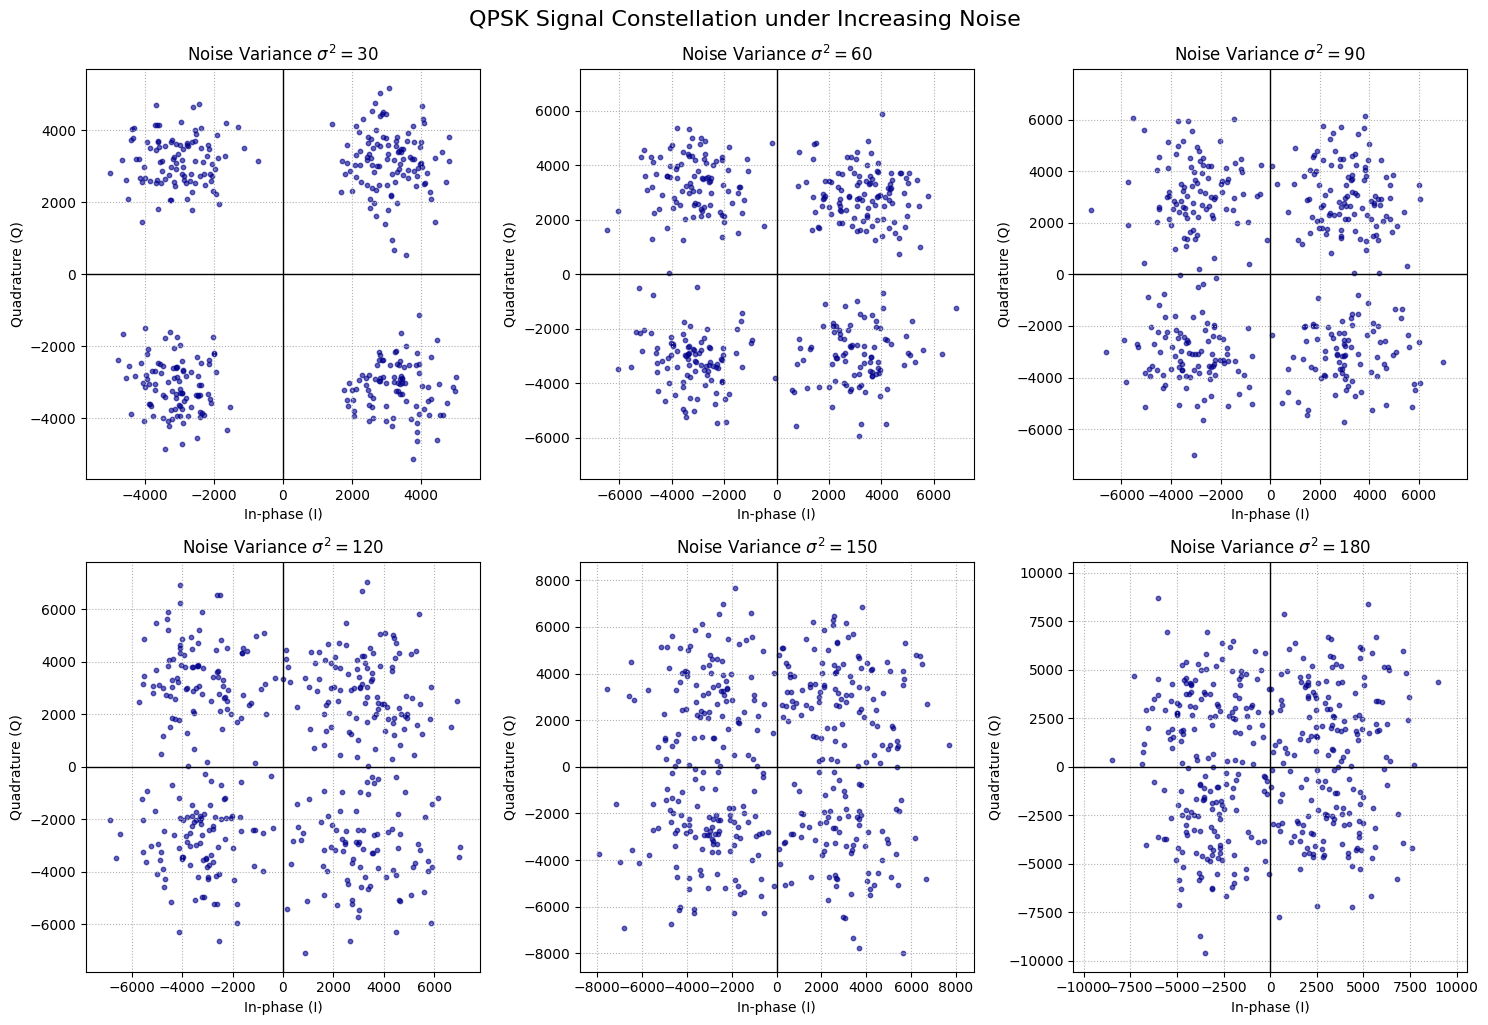

In [25]:
# ---------------------------------------------------------
# Part (c): Signal Constellation Visualization
# ---------------------------------------------------------

variance_values = [30, 60, 90, 120, 150, 180]
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

print("\n--- Generating Constellation Diagrams ---")

for i, var in enumerate(variance_values):
    sigma = np.sqrt(var)
    
    # 1. Channel & Noise
    rx_attenuated, _ = Channel_Model(tx_signal, length_km)
    rx_noisy = apply_noise(rx_attenuated, sigma)
    
    # 2. Demodulation & Matched Filter
    yI_rec, yQ_rec = AnalogDemod(rx_noisy, fc, fs, bw_baseband)
    filt_I = Matched_Filter(yI_rec, pulse_shape)
    filt_Q = Matched_Filter(yQ_rec, pulse_shape)
    
    # 3. Sampling at the peak of the pulse
    num_symbols = len(bits_I)
    sampling_indices = (np.arange(1, num_symbols + 1) * samples_per_pulse) - 1
    sampling_indices = sampling_indices[sampling_indices < len(filt_I)]
    
    samples_I = filt_I[sampling_indices]
    samples_Q = filt_Q[sampling_indices]
    
    # 4. Plotting the Constellation
    axes[i].scatter(samples_I, samples_Q, alpha=0.6, s=10, color='darkblue')
    axes[i].axhline(0, color='black', linewidth=1)
    axes[i].axvline(0, color='black', linewidth=1)
    axes[i].set_title(f'Noise Variance $\sigma^2 = {var}$')
    axes[i].set_xlabel('In-phase (I)')
    axes[i].set_ylabel('Quadrature (Q)')
    axes[i].grid(True, linestyle=':')
    
    # Set axis limits to keep plots comparable
    limit = max(np.max(np.abs(samples_I)), np.max(np.abs(samples_Q))) * 1.1
    axes[i].set_xlim(-limit, limit)
    axes[i].set_ylim(-limit, limit)

plt.tight_layout()
plt.suptitle('QPSK Signal Constellation under Increasing Noise', fontsize=16, y=1.02)
plt.show()

### Part 4 :
Plot the eye diagram of the received signal for different noise variances and analyze its main components.

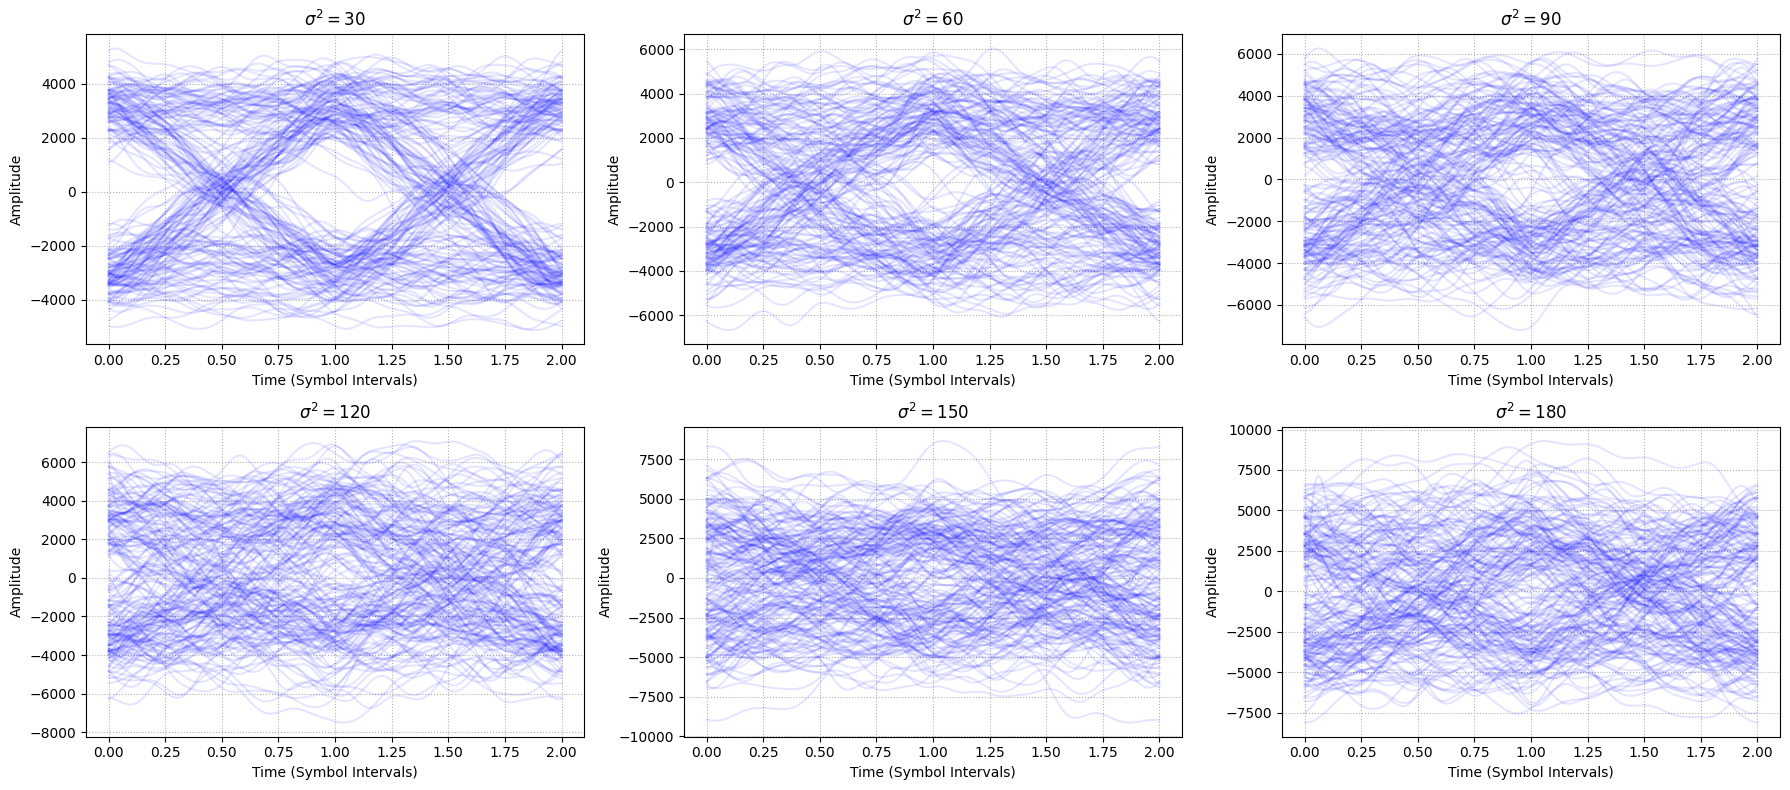

In [26]:
# --------------------------------------
# Part (d): Eye Diagram
# --------------------------------------

def plot_eye_diagram(signal_data, samples_per_symbol, num_eyes=2, title="Eye Diagram"):
    """
    Plots an eye diagram by overlapping segments of the signal.
    """
    segment_length = samples_per_symbol * num_eyes
    num_segments = len(signal_data) // segment_length

    t_eye = np.linspace(0, num_eyes, segment_length)

    for i in range(num_segments):
        segment = signal_data[i*segment_length : (i+1)*segment_length]
        plt.plot(t_eye, segment, color='blue', alpha=0.1)

    plt.title(title)
    plt.xlabel("Time (Symbol Intervals)")
    plt.ylabel("Amplitude")
    plt.grid(True, linestyle=':')

# --- Execution for Part (d) ---
selected_variances = [30, 60, 90, 120, 150, 180]

plt.figure(figsize=(18, 8))  # Wider figure for 3 plots in a row

for idx, var in enumerate(selected_variances):
    sigma = np.sqrt(var)

    # Simulate signal through channel and demodulator
    rx_attenuated, _ = Channel_Model(tx_signal, length_km)
    rx_noisy = apply_noise(rx_attenuated, sigma)
    yI_rec, _ = AnalogDemod(rx_noisy, fc, fs, bw_baseband)
    filt_I = Matched_Filter(yI_rec, pulse_shape)

    data_to_plot = filt_I[samples_per_pulse : -samples_per_pulse]

    # Create subplot (2 rows, 3 columns)
    plt.subplot(2, 3, idx + 1)
    plot_eye_diagram(
        data_to_plot,
        samples_per_pulse,
        title=f"$\\sigma^2 = {var}$"
    )

plt.tight_layout()
plt.show()


## Testing for QPSK 

In [ ]:
# =====================================================================#
# Connecting all the Blocks and Testing it with a 150-letter string    #
# =====================================================================#

# --- 1. System Parameters ---
fs = 1e6              # Sampling Frequency: 1 MHz 
fc = 10e3             # Carrier Frequency: 10 kHz 
T_pulse = 0.01        # Pulse Duration: 10 ms 
samples_per_pulse = int(T_pulse * fs)
length_km = 10.0      # Channel distance: 10 km 
bw_lpf = 500          # LPF Bandwidth (Hz) 
var = 30
sigma_noise = np.sqrt(var)   

# --- 2. Transmitter Block ---

# Step A: Information Source 
L = 150
source_sequence = generate_data(L)

# Step B: Source Coding (Huffman) 
prob_dict = {
    'A': 0.25, 'B': 0.20, 'C': 0.15, 'D': 0.10, 'E': 0.08,
    'F': 0.07, 'G': 0.05, 'H': 0.04, 'I': 0.04, 'J': 0.02
}
huff_codes = Huffman_code(prob_dict)
huffman_bits = source_coder(source_sequence, huff_codes)

# Step C: Channel Coding (Hamming 7,4)
hamming_bits = Hamming_coder(huffman_bits)

# Step D: QPSK Modulation Preparation 
# Ensure even bit length for QPSK symbol pairs
if len(hamming_bits) % 2 != 0:
    hamming_bits += '0'

# Split into In-phase (I) and Quadrature (Q) streams
bits_I = hamming_bits[0::2]
bits_Q = hamming_bits[1::2]

# Step E: Pulse Shaping (Bipolar Mapping: 0 -> -1, 1 -> +1) 
pulse_shape = np.ones(samples_per_pulse) # Rectangular pulse
sig_I_unipolar = Pulse_Shaping(bits_I, pulse_shape)
sig_Q_unipolar = Pulse_Shaping(bits_Q, pulse_shape)

sig_I = 2 * sig_I_unipolar - 1
sig_Q = 2 * sig_Q_unipolar - 1

# Step F: Analog Modulation 
# s(t) = I*cos(2πfct) - Q*sin(2πfct)
mod_I, t = Analog_Mod(sig_I, fc, fs)
carrier_sin = np.sin(2 * np.pi * fc * t)
mod_Q = sig_Q * (-carrier_sin)
tx_signal = mod_I + mod_Q

# --- 3. Channel & Noise Block ---

# Step G: Channel Attenuation and AWGN 
rx_attenuated, linear_gain = Channel_Model(tx_signal, length_km)

rx_noisy = apply_noise(rx_attenuated, sigma_noise)
# --- 4. Receiver Block ---

# Step H: Analog Demodulation
yI_raw, yQ_raw = AnalogDemod(rx_noisy, fc, fs, bw_lpf)

# Step I: Matched Filtering 
# Optimal filtering for AWGN channels
filt_I = Matched_Filter(yI_raw, pulse_shape)
filt_Q = Matched_Filter(yQ_raw, pulse_shape)

# Step J: Detection & Decision (Refined)
# 1. Normalize by the pulse energy so the peak is roughly 1.0
# Ensure we sample at the peak of the matched filter convolution
sampling_indices = (np.arange(1, len(bits_I) + 1) * samples_per_pulse) - 1
energy = np.sum(pulse_shape**2)
samples_I = filt_I[sampling_indices] / energy
samples_Q = filt_Q[sampling_indices] / energy

# 2. Hard Decision
dec_I = ['1' if s > 0 else '0' for s in samples_I]
dec_Q = ['1' if s > 0 else '0' for s in samples_Q]

# Step K: Reconstruct Bit Stream
recovered_hamming = "".join(i + q for i, q in zip(dec_I, dec_Q))

# Step L: Channel Decoding (Hamming 7,4 Correction) 
recovered_huffman = Hamming_decoder(recovered_hamming)

# Step M: Source Decoding (Huffman)
# Match original sequence length L
recovered_sequence = source_decoder(recovered_huffman, huff_codes)[:L]

# --- 5. Verification & Results ---
print("--- QPSK System Results ---")
print(f"Original Sequence (start):  {source_sequence[:30]}...")
print(f"Recovered Sequence (start): {recovered_sequence[:30]}...")


print("\n" + "="*50)
print(f"RESULTS (Dist: {length_km}km, Noise Var: {var})")
print("="*50)

# Calculate Bit Error Rate (BER)
errors = sum(c1 != c2 for c1, c2 in zip(hamming_bits, recovered_hamming))
ber = errors / len(hamming_bits)

print(f"Transmission Gain:      {gain:.4f} (-{length_km:.1f} dB)")
print(f"Raw Bit Errors:         {errors} / {len(hamming_bits)}")
print(f"Raw BER:                {ber:.4f}")
print("-" * 50)



--- QPSK System Results ---
Original Sequence (start):  CBACDBBBAAACDCBAHFFBIGFDCAACAI...
Recovered Sequence (start): CBACDBBBAAACDCBAHFFBIGFDCAACAI...

RESULTS (Dist: 10.0km, Noise Var: 30)
Transmission Gain:      0.3162 (-10.0 dB)
Raw Bit Errors:         0 / 826
Raw BER:                0.0000
--------------------------------------------------


## 16-QAM Modulation
    In this section, we want to change our modulation scheme to 16-QAM. Based on what you learned in class, theoretically determine the amplitudes of the 16 signals required to transmit groups of 4 bits.

### Part a :
Generate a sequence of length L (sufficiently long) from the alphabet given in Table 1. Then, using the functions source_coder and Hamming_coder, convert it into a binary sequence consisting of 0s and 1s.

In [28]:
# ---------------------------------------------------------
# 1. Main Execution 
# ---------------------------------------------------------

# A) Generate a long sequence L
L = 150
source_sequence = generate_data(L)

# Define Probabilities
prob_dict = {
    'A': 0.25, 'B': 0.20, 'C': 0.15, 'D': 0.10, 'E': 0.08,
    'F': 0.07, 'G': 0.05, 'H': 0.04, 'I': 0.04, 'J': 0.02
}

# B) Apply Source Coding
huff_codes = Huffman_code(prob_dict)
huffman_bits = source_coder(source_sequence, huff_codes)

# C) Apply Channel Coding
hamming_bits = Hamming_coder(huffman_bits)

# D) Prepare for QPSK (Ensure even length)
# QPSK takes 2 bits per symbol, so total bits must be even.
if len(hamming_bits) % 2 != 0:
    hamming_bits += '0'

# ---------------------------------------------------------
# 2. Results & Verification
# ---------------------------------------------------------
print(f"--- 16-QAM Part (a): Data Generation ---")
print(f"1. Original Sequence Bits(L={L}): {source_sequence[:15]}...")
print(f"2. Huffman Encoded Bits: {huffman_bits[:20]}... (Total Len: {len(huffman_bits)})")
print(f"3. Hamming Encoded Bits: {hamming_bits[:20]}... (Total Len: {len(hamming_bits)})")


--- 16-QAM Part (a): Data Generation ---
1. Original Sequence Bits(L=150): DBACDCEHFBABCAB...
2. Huffman Encoded Bits: 01000101100101101110... (Total Len: 417)
3. Hamming Encoded Bits: 10011000100101001100... (Total Len: 736)


### Part b:
Using the pulse_shaping functions and the four signal waveforms, convert the bit stream into a single signal that is ready to be modulated by Analog_mod. Now, assuming that AWGN noise is added to the signal after it passes through the channel, plot the error probability as a function of the noise variance. Choose a sufficiently large range for the horizontal axis. Pay attention to the behavior of the error probability. Consider $σ^2$ with step sizes of 30, and vary the noise variance from $σ^2=30$ up to $σ^2=180$.

Variance   | Sigma      | BER       
------------------------------------
30         | 5.4772     | 0.000000  
60         | 7.7460     | 0.000000  
90         | 9.4868     | 0.008838  
120        | 10.9545    | 0.015152  
150        | 12.2474    | 0.025253  
180        | 13.4164    | 0.037879  


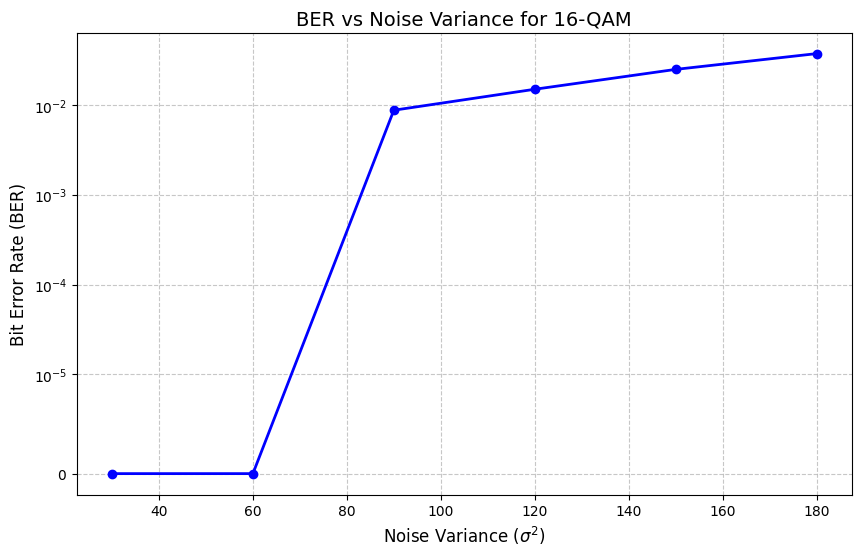

In [77]:
# ---------------------------------------------
# PART (b): 16-QAM Modulation & Noise Analysis
# ---------------------------------------------

# --- Main Processing for 16-QAM ---

# System parameters according to Table 2
fs = 1e6            # 1 MHz sampling frequency
T_pulse = 10e-3     # 10 ms pulse duration
fc = 10e3           # 10 kHz carrier frequency
samples_per_pulse = int(fs * T_pulse)
pulse_shape = np.ones(samples_per_pulse)  # Rectangular pulse

# Gray mapping for PAM-4 levels
# Bits -> Level: 00->-3, 01->-1, 11->+1, 10->+3
gray_map = {
    '00': -3,
    '01': -1,
    '11': 1,
    '10': 3
}

# --- Adjust bitstream length for 16-QAM ---
# Number of extra bits needed to make length a multiple of 4
remainder = len(hamming_bits) % 4
if remainder != 0:
    padding_needed = 4 - remainder
    hamming_bits += '0' * padding_needed
    print(f"Added {padding_needed} bits as padding.")

# Now execute Part (a):
I_levels = []
Q_levels = []
input_bit_chunks = []

for i in range(0, len(hamming_bits), 4):
    chunk = hamming_bits[i:i+4]
    input_bit_chunks.append(chunk)
    
    bits_I = chunk[0:2]
    bits_Q = chunk[2:4]
    
    I_levels.append(gray_map[bits_I])
    Q_levels.append(gray_map[bits_Q])

# --- (a) Convert bits to I and Q levels ---
I_levels = []
Q_levels = []
input_bit_chunks = []  # For final comparison

for i in range(0, len(hamming_bits), 4):
    chunk = hamming_bits[i:i+4]
    input_bit_chunks.append(chunk)
    
    # First two bits for I, next two bits for Q
    bits_I = chunk[0:2]
    bits_Q = chunk[2:4]
    
    I_levels.append(gray_map[bits_I])
    Q_levels.append(gray_map[bits_Q])

# --- (b) Pulse Shaping (Construct continuous-time signal) ---
# Create signal by repeating voltage level over pulse duration
sig_I = np.repeat(I_levels, samples_per_pulse)
sig_Q = np.repeat(Q_levels, samples_per_pulse)

# --- (c) Analog Modulation ---
# Formula: x(t) = I(t)cos(wt) - Q(t)sin(wt)
t = np.arange(len(sig_I)) / fs
carrier_cos = np.cos(2 * np.pi * fc * t)
carrier_sin = np.sin(2 * np.pi * fc * t)

# Transmitted modulated signal
tx_signal = (sig_I * carrier_cos) - (sig_Q * carrier_sin)

# --- (d) Channel Simulation and BER Calculation ---
noise_variances = np.arange(30, 181, 30)  # 30, 60, 90, 120, 150, 180
ber_results = []

print(f"{'Variance':<10} | {'Sigma':<10} | {'BER':<10}")
print("-" * 36)

# Channel length (assumed 0 or small since focus is noise effect)
channel_len = 10 

# Pass through channel (without noise first)
# Note: Channel_Model applies attenuation
attenuated_signal, channel_gain = Channel_Model(tx_signal, channel_len)

for var in noise_variances:
    sigma = np.sqrt(var)
    
    # 1. Add noise
    rx_signal = apply_noise(attenuated_signal, sigma)
    
    # 2. Coherent Demodulation
    # Multiply by carriers (factor 2 compensates cosine/sine amplitude)
    # y_I = rx * 2cos(wt), y_Q = rx * -2sin(wt)
    demod_I_input = rx_signal * (2 * carrier_cos)
    demod_Q_input = rx_signal * (-2 * carrier_sin)
    
    # 3. Matched Filter
    # Convolution output is longer; correct sampling points must be selected
    mf_out_I = Matched_Filter(demod_I_input, pulse_shape)
    mf_out_Q = Matched_Filter(demod_Q_input, pulse_shape)
    
    # 4. Sampling and Decision
    detected_bits = ""
    num_errors = 0
    total_bits = 0
    
    # Pulse energy normalization factor:
    # Amplitude * Pulse_Length (Samples) * Channel_Gain
    # Since rectangular pulse with amplitude 1 is used:
    normalization_factor = samples_per_pulse * channel_gain
    
    # Sample at the end of each pulse period
    # Indices: samples_per_pulse-1, 2*samples_per_pulse-1, ...
    for k in range(len(I_levels)):
        sample_idx = (k + 1) * samples_per_pulse - 1
        
        # Get normalized I and Q values
        val_I = mf_out_I[sample_idx] / normalization_factor
        val_Q = mf_out_Q[sample_idx] / normalization_factor
        
        # Decision function (Slicer) to nearest level (-3, -1, 1, 3)
        def detect_level(v):
            if v < -2: return -3
            elif v < 0: return -1
            elif v < 2: return 1
            else: return 3
            
        det_lev_I = detect_level(val_I)
        det_lev_Q = detect_level(val_Q)
        
        # Convert level back to bits (Inverse Gray Mapping)
        # Levels: -3->00, -1->01, 1->11, 3->10
        def level_to_bits(lev):
            if lev == -3: return '00'
            if lev == -1: return '01'
            if lev == 1:  return '11'
            if lev == 3:  return '10'
            return '00'  # Default
            
        rec_bits = level_to_bits(det_lev_I) + level_to_bits(det_lev_Q)
        
        # Compare with transmitted bits
        orig_bits = input_bit_chunks[k]
        for b_orig, b_rec in zip(orig_bits, rec_bits):
            if b_orig != b_rec:
                num_errors += 1
            total_bits += 1
            
    ber = num_errors / total_bits
    ber_results.append(ber)
    print(f"{var:<10} | {sigma:<10.4f} | {ber:<10.6f}")

# --- Plot Results ---
plt.figure(figsize=(10, 6))
plt.plot(noise_variances, ber_results, marker='o', linestyle='-', color='b', linewidth=2)
plt.title('BER vs Noise Variance for 16-QAM', fontsize=14)
plt.xlabel('Noise Variance ($\sigma^2$)', fontsize=12)
plt.ylabel('Bit Error Rate (BER)', fontsize=12)
plt.grid(True, which='both', linestyle='--', alpha=0.7)
plt.yscale('symlog', linthresh=1e-5)
plt.show()


### Part 3 :
Based on the previous section, choose 6 different values for the noise variance and plot the signal constellation.

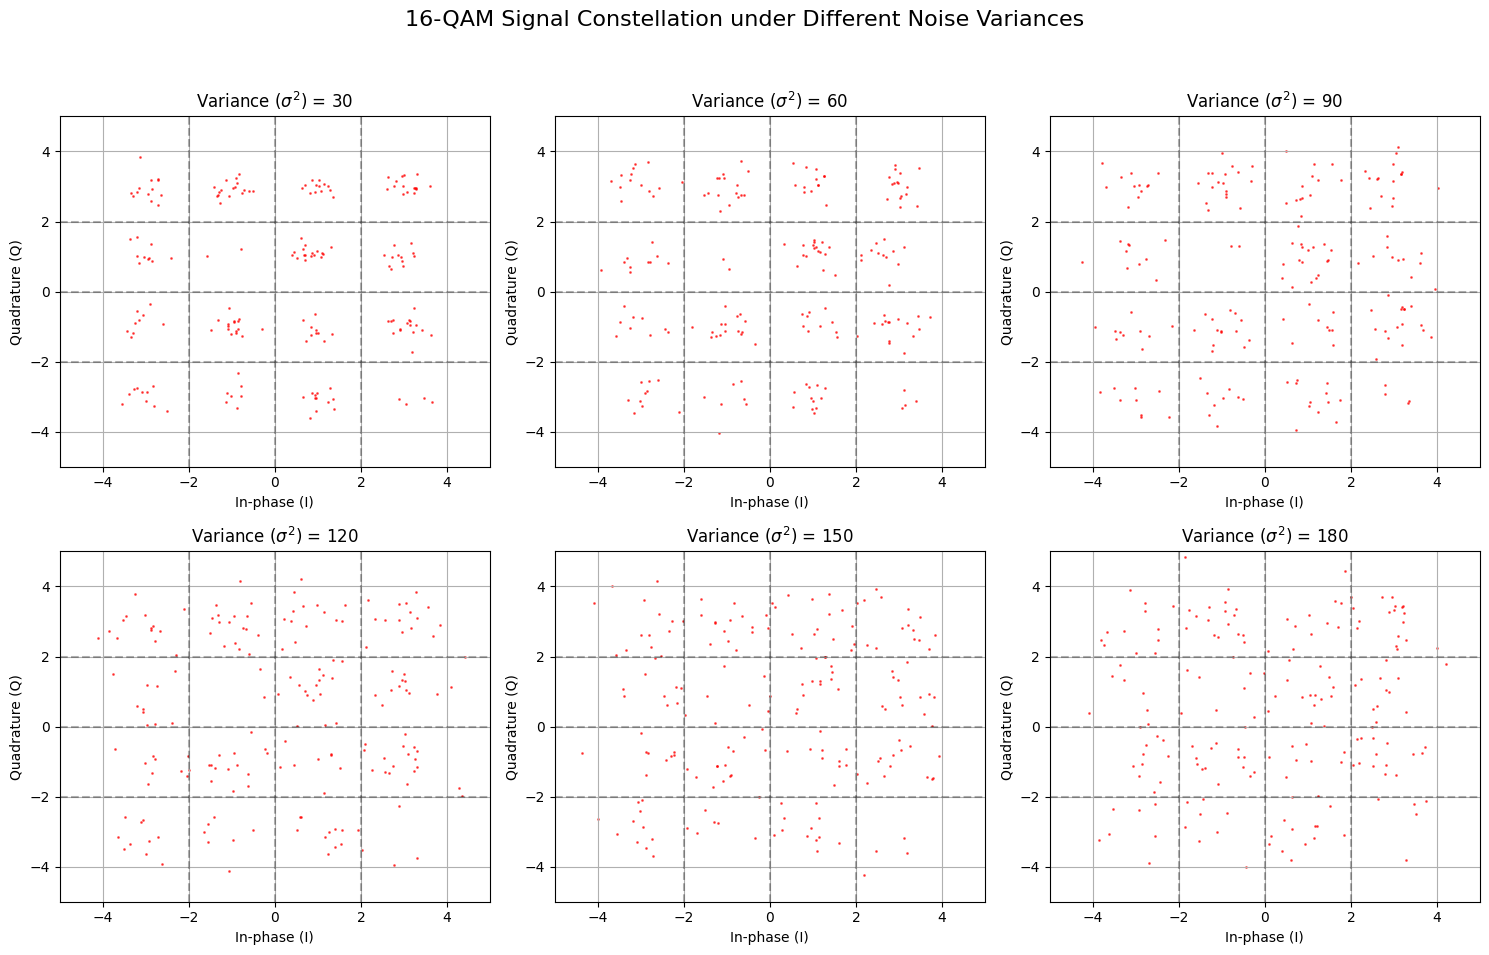

In [33]:
# ---------------------------------------------------------
# Part (c): Signal Constellation Visualization
# ---------------------------------------------------------

noise_variances = [30, 60, 90, 120, 150, 180]

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('16-QAM Signal Constellation under Different Noise Variances', fontsize=16)

axes = axes.flatten()

for i, var in enumerate(noise_variances):
    sigma = np.sqrt(var)
    
    # 1. Add noise to the signal after passing through the channel
    rx_signal = apply_noise(attenuated_signal, sigma)
    
    # 2. Demodulation (multiply by carrier signals)
    demod_I = rx_signal * (2 * carrier_cos)
    demod_Q = rx_signal * (-2 * carrier_sin)
    
    # 3. Matched filtering
    mf_out_I = Matched_Filter(demod_I, pulse_shape)
    mf_out_Q = Matched_Filter(demod_Q, pulse_shape)
    
    # 4. Sampling at optimal sampling points
    # The matched filter output at the end of each pulse interval has maximum SNR
    sampled_I = []
    sampled_Q = []
    
    normalization_factor = samples_per_pulse * channel_gain
    
    for k in range(len(I_levels)):
        sample_idx = (k + 1) * samples_per_pulse - 1
        sampled_I.append(mf_out_I[sample_idx] / normalization_factor)
        sampled_Q.append(mf_out_Q[sample_idx] / normalization_factor)
    
    # 5. Plot the constellation
    axes[i].scatter(sampled_I, sampled_Q, s=1, alpha=0.6, color='red')
    axes[i].set_title(f'Variance ($\sigma^2$) = {var}')
    axes[i].set_xlabel('In-phase (I)')
    axes[i].set_ylabel('Quadrature (Q)')
    axes[i].grid(True)
    
    # Draw decision boundaries for clarity
    for line in [-2, 0, 2]:
        axes[i].axhline(line, color='black', linestyle='--', alpha=0.3)
        axes[i].axvline(line, color='black', linestyle='--', alpha=0.3)
    
    axes[i].set_xlim([-5, 5])
    axes[i].set_ylim([-5, 5])

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


### Part 4 :
Plot the eye diagram of the received signal for different noise variances and analyze its main components.

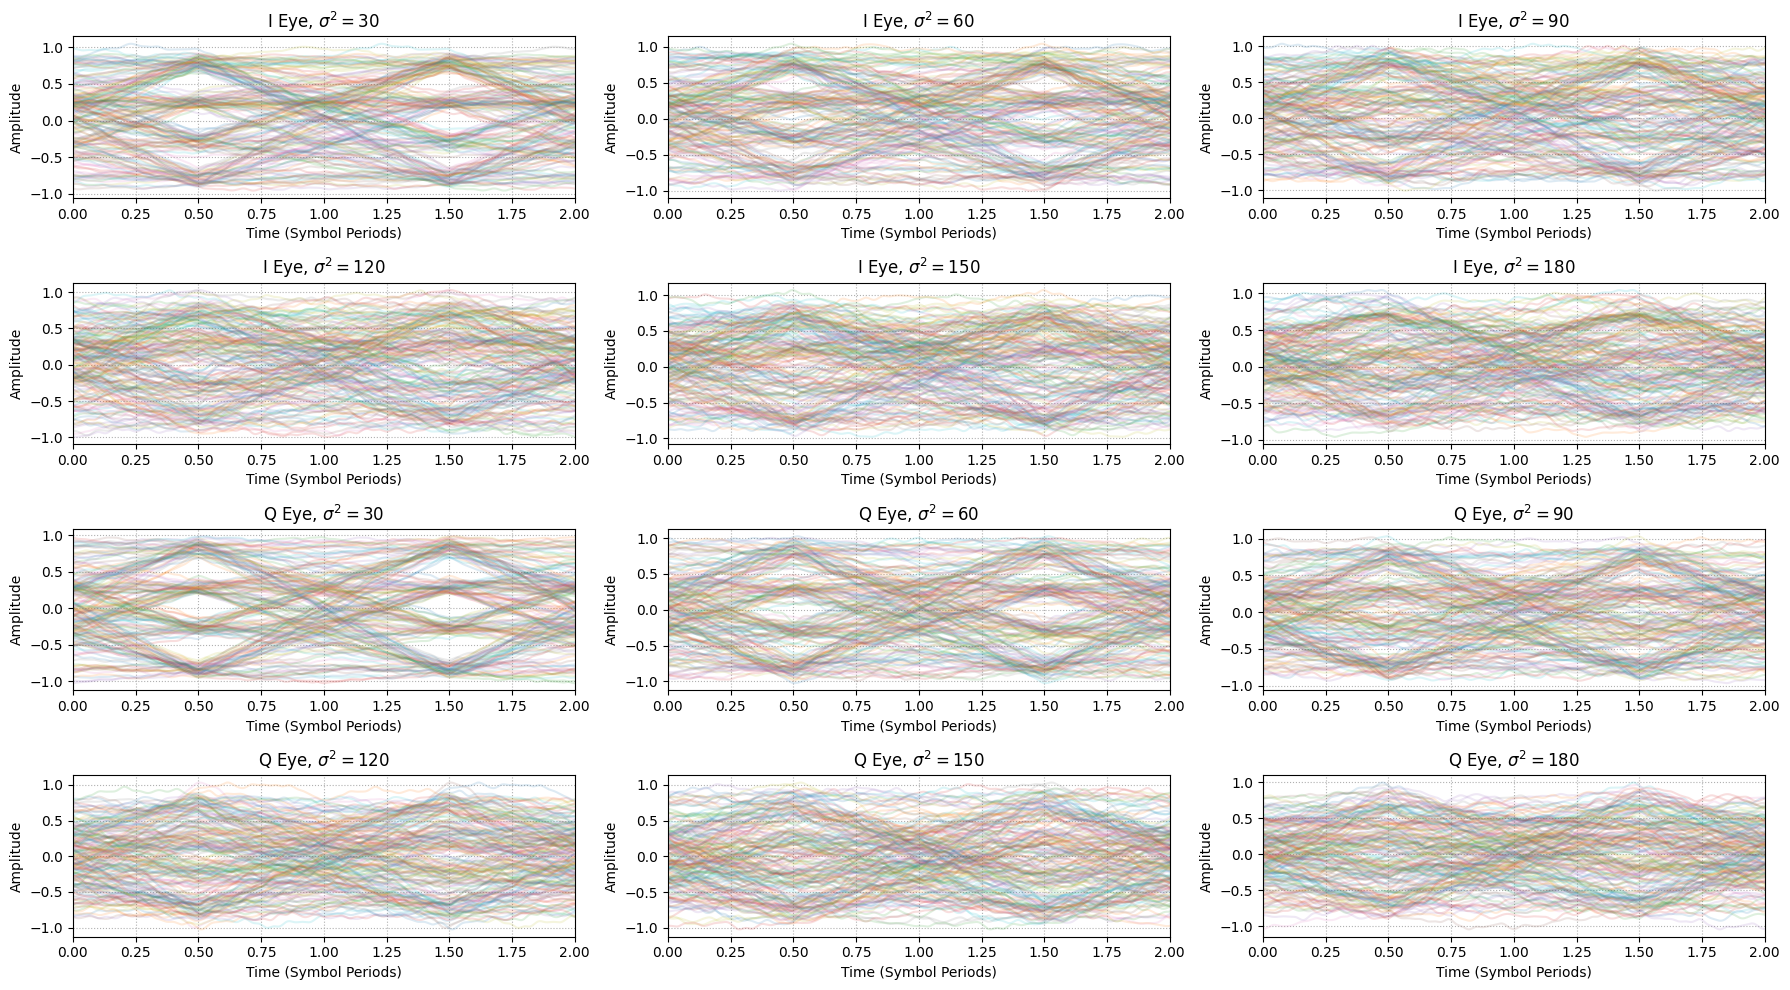

In [ ]:
# --------------------------------------
# Eye Diagram Function 
# --------------------------------------

def plot_eye_diagram(signal_data, samples_per_symbol, num_eyes=2, title="Eye Diagram"):
    segment_length = samples_per_symbol * num_eyes
    total_segments = len(signal_data) // samples_per_symbol - 1
    max_segments = min(300, total_segments)

    t = np.arange(segment_length) / samples_per_symbol  # normalized time axis

    for i in range(max_segments):
        start = i * samples_per_symbol
        segment = signal_data[start : start + segment_length]

        if len(segment) == segment_length:
            plt.plot(t, segment, alpha=0.15)

    plt.title(title)
    plt.xlabel("Time (Symbol Periods)")
    plt.ylabel("Amplitude")
    plt.xlim(0, num_eyes)
    plt.grid(True, linestyle=':')



# ----------------------------------
# 16-QAM Eye Diagram Execution
# ----------------------------------

selected_variances = [30, 60, 90, 120, 150, 180]


plt.figure(figsize=(18, 10))

for idx, var in enumerate(selected_variances):
    sigma = np.sqrt(var)

    # 1. Channel Model
    rx_attenuated, _ = Channel_Model(tx_signal, length_km)
    
    # 2. Add Noise
    rx_noisy = apply_noise(rx_attenuated, sigma)

    # 3. Demodulate
    yI_rec, yQ_rec = AnalogDemod(rx_noisy, fc, fs, bw_baseband)

    # 4. Matched filtering
    filt_I = Matched_Filter(yI_rec, pulse_shape)
    filt_Q = Matched_Filter(yQ_rec, pulse_shape)

    # 5. Remove filter transients
    filt_I = filt_I[samples_per_pulse : -samples_per_pulse]
    filt_Q = filt_Q[samples_per_pulse : -samples_per_pulse]

    # 6. Align to symbol center
    offset = samples_per_pulse // 2
    aligned_I = filt_I[offset:]
    aligned_Q = filt_Q[offset:]

    # 7. Normalize
    # We use a robust normalization to prevent noise spikes from shrinking the plot
    norm_factor_I = np.percentile(np.abs(aligned_I), 99.9)
    norm_factor_Q = np.percentile(np.abs(aligned_Q), 99.9)
    
    aligned_I = aligned_I / norm_factor_I
    aligned_Q = aligned_Q / norm_factor_Q

    # -----------------------
    # Plot I Eye
    # -----------------------
    plt.subplot(4, 3, idx + 1)
    plot_eye_diagram(
        aligned_I,
        samples_per_pulse,
        title=f"I Eye, $\\sigma^2 = {var}$"
    )

    # -----------------------
    # Plot Q Eye
    # -----------------------
    plt.subplot(4, 3, idx + 7)
    plot_eye_diagram(
        aligned_Q,
        samples_per_pulse,
        title=f"Q Eye, $\\sigma^2 = {var}$"
    )

plt.tight_layout()
plt.show()

## Testing for 16-QAM

In [78]:
# =====================================================================#
# Connecting all the Blocks and Testing it with a 150-letter string    #
# =====================================================================#

# --- Main System Parameters ---
fs = 1e6            # Sampling frequency
fc = 10e3           # Carrier frequency
T_pulse = 10e-3     # Pulse duration (10 milliseconds)
samples_per_pulse = int(fs * T_pulse)
pulse_shape = np.ones(samples_per_pulse)  # Rectangular pulse
bw_baseband = 20 / T_pulse                 # Demodulator filter bandwidth
length_km = 10.0                          # Channel distance
Variance = 30   
sigma = np.sqrt(Variance)                        

# Gray mapping for 16-QAM
gray_map = {'00': -3, '01': -1, '11': 1, '10': 3}
inv_gray_map = {v: k for k, v in gray_map.items()}

# 1. Generate random data (150 characters)
data_string = generate_data(150)
print(f"Original Data (first 20 chars): {data_string[:20]}")

# 2. Source coding (Huffman)
alphabet_probs = {
    'A': 0.25, 'B': 0.20, 'C': 0.15, 'D': 0.10,
    'E': 0.08, 'F': 0.07, 'G': 0.05, 'H': 0.04,
    'I': 0.04, 'J': 0.02
}
huffman_dict = Huffman_code(alphabet_probs)
source_bits = source_coder(data_string, huffman_dict)

# 3. Channel coding (Hamming 7,4)
hamming_bits = Hamming_coder(source_bits)

# Padding for 16-QAM (number of bits must be a multiple of 4)
remainder = len(hamming_bits) % 4
if remainder != 0:
    hamming_bits += '0' * (4 - remainder)

# 4. 16-QAM Modulation
I_levels, Q_levels = [], []
for i in range(0, len(hamming_bits), 4):
    chunk = hamming_bits[i:i+4]
    I_levels.append(gray_map[chunk[0:2]])  # First two bits for I
    Q_levels.append(gray_map[chunk[2:4]])  # Last two bits for Q

# Pulse shaping
sig_I = np.repeat(I_levels, samples_per_pulse)
sig_Q = np.repeat(Q_levels, samples_per_pulse)

# Analog modulation
t = np.arange(len(sig_I)) / fs
tx_signal = (sig_I * np.cos(2 * np.pi * fc * t)) - \
            (sig_Q * np.sin(2 * np.pi * fc * t))

# 5. Channel model and noise (AWGN)
rx_attenuated, linear_gain = Channel_Model(tx_signal, length_km)
rx_noisy = apply_noise(rx_attenuated, sigma)

# 6. Demodulation and matched filtering
yI_rec, yQ_rec = AnalogDemod(rx_noisy, fc, fs, bw_baseband)

# Using your Matched_Filter function
filt_I_full = Matched_Filter(yI_rec, pulse_shape)
filt_Q_full = Matched_Filter(yQ_rec, pulse_shape)

# Normalization and channel attenuation compensation
# The matched filter with a rectangular pulse multiplies
# the amplitude by samples_per_pulse
normalization = samples_per_pulse * linear_gain
filt_I = filt_I_full / normalization
filt_Q = filt_Q_full / normalization

# 7. Sampling and Detection
def slicer(v):
    # Map the received voltage to the nearest valid level (-3, -1, 1, 3)
    levels = np.array([-3, -1, 1, 3])
    return levels[np.argmin(np.abs(levels - v))]

recovered_hamming_bits = ""

# Sampling at the end of each pulse period
# (considering matched filter delay)
for k in range(len(I_levels)):
    sample_idx = (k + 1) * samples_per_pulse - 1
    lev_I = slicer(filt_I[sample_idx])
    lev_Q = slicer(filt_Q[sample_idx])
    recovered_hamming_bits += inv_gray_map[lev_I] + inv_gray_map[lev_Q]

# 8. Channel and source decoding
# Remove extra padding bits if necessary,
# but the Hamming (7,4) decoder works on 7-bit blocks
decoded_source_bits = Hamming_decoder(recovered_hamming_bits)
recovered_data = source_decoder(decoded_source_bits, huffman_dict)

# --- 8. Verification & Results ---
print("--- 16-QAM System Results ---")
print(f"Original Sequence (start):  {data_string[:30]}...")
print(f"Recovered Sequence (start): {recovered_data[:30]}...")

print("\n" + "="*50)
print(f"RESULTS (Dist: {length_km}km, Noise Var: {Variance})")
print("="*50)

# Calculate Bit Error Rate (BER)x
errors = sum(c1 != c2 for c1, c2 in zip(hamming_bits, recovered_hamming_bits))
ber = errors / len(hamming_bits)

print(f"Transmission Gain:      {gain:.4f} (-{length_km:.1f} dB)")
print(f"Raw Bit Errors:         {errors} / {len(hamming_bits)}")
print(f"Raw BER:                {ber:.4f}")
print("-" * 50)


Original Data (first 20 chars): EBBAADCAACCACEAJAAFD
--- 16-QAM System Results ---
Original Sequence (start):  EBBAADCAACCACEAJAAFDAFIBFBACBI...
Recovered Sequence (start): EBBAADCAACCACEAJAAFDAFIBFBACBI...

RESULTS (Dist: 10.0km, Noise Var: 30)
Transmission Gain:      0.3162 (-10.0 dB)
Raw Bit Errors:         0 / 764
Raw BER:                0.0000
--------------------------------------------------
